In [1]:
%pip install pandas requests matplotlib

import requests
import pandas as pd
import matplotlib.pyplot as plt
import time
import json
import re

from datetime import datetime, timedelta, timezone

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
GAMES = {
    "Cyberpunk 2077": 1091500,
    "No Man's Sky": 275850,
    "Helldivers 2": 553850,
    "Elden Ring": 1245620
}

GAME = "Cyberpunk 2077"
APP_ID = GAMES[GAME]

WINDOW_DAYS = 14

print(f"Selected game: {GAME}")
print(f"Steam App ID: {APP_ID}")

Selected game: Cyberpunk 2077
Steam App ID: 1091500


In [3]:
# Collect update news that looks patch related

NEWS_URL = "https://api.steampowered.com/ISteamNews/GetNewsForApp/v2/"
REVIEWS_URL = "https://api.steampowered.com/IUserReviewsService/GetAppReviews/v1/"

session = requests.Session()

# returns json format of requested url api request
def get_json(url, params):
    for attempt in range(4):
        response = session.get(url, params=params, timeout=30)

        if response.status_code in [429, 500, 502, 503, 504]:
            if attempt == 3:
                response.raise_for_status()

            wait = min(60, 5 * (2 ** attempt))
            time.sleep(wait)
            continue

        response.raise_for_status()
        return response.json()


#scrapes the pages for news, finds update/patch related announcements
def get_patch_news(app_id, max_pages=3):
    news = []
    enddate = None

    for page in range(max_pages):
        params = {
            "appid": app_id,
            "count": 100,
            "maxlength": 1000
        }

        if enddate is not None:
            params["enddate"] = enddate

        data = get_json(NEWS_URL, params)
        batch = data.get("appnews", {}).get("newsitems", [])

        if not batch:
            break

        news.extend(batch)
        enddate = min(item["date"] for item in batch) - 1

        time.sleep(1.5)

    df = pd.DataFrame(news)

    if df.empty:
        return df

    df = df.drop_duplicates(subset="gid")

    df["date"] = pd.to_datetime(
        df["date"], unit="s", utc=True
    )

    # Find announcements that might be patches
    pattern = r"\b(patch|hotfix|update|fixes|changelog)\b"

    df["is_patch_candidate"] = df["title"].str.contains(
        pattern, case=False, regex=True, na=False
    )

    return df.sort_values("date", ascending=False)

In [4]:
patches_df = get_patch_news(APP_ID)

patch_candidates = patches_df[
    patches_df["is_patch_candidate"]
]

display(patch_candidates[["date", "title", "url"]].head(25))

patches_df.to_csv("cyberpunk_news.csv", index=False)

/tmp/ipykernel_3411367/2810395493.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


,date,title,url
40,2026-10-22 10:12:54+00:00,Cyberpunk 2077 Edgerunners update brings impro...,https://steamstore-a.akamaihd.net/news/externa...
41,2026-10-22 10:06:54+00:00,Cyberpunk 2077's Edgerunners 2 Update (2.5) is...,https://steamstore-a.akamaihd.net/news/externa...
44,2026-10-21 16:09:58+00:00,Cyberpunk 2077's Edgerunners 2 update adds two...,https://steamstore-a.akamaihd.net/news/externa...
48,2026-10-21 15:45:15+00:00,Check out what's coming to Cyberpunk 2077 in t...,https://steamstore-a.akamaihd.net/news/externa...
54,2026-10-20 10:00:33+00:00,REDstreams — Cyberpunk 2077: Edgerunners 2 Upd...,https://steamstore-a.akamaihd.net/news/externa...
158,2025-09-11 14:58:15+00:00,CDPR returns to the fridge for one more Cyberp...,https://steamstore-a.akamaihd.net/news/externa...
159,2025-09-11 10:09:03+00:00,Patch 2.31,https://steamstore-a.akamaihd.net/news/externa...
172,2025-07-16 17:52:27+00:00,Seven months after putting Johnny Silverhand i...,https://steamstore-a.akamaihd.net/news/externa...
173,2025-07-16 16:12:59+00:00,Cyberpunk 2077 update 2.3 motors into your lif...,https://steamstore-a.akamaihd.net/news/externa...
174,2025-07-16 16:12:38+00:00,Update 2.3 Patch Notes,https://steamstore-a.akamaihd.net/news/externa...


In [5]:
# Collect steam reviews within a start and end date
def get_reviews(app_id, start_date, end_date,
                max_pages=3, language="english"):

    reviews = []
    cursor = "*"
    seen_cursors = set()
    page = 0

    start_ts = int(pd.Timestamp(start_date).timestamp())
    end_ts = int(pd.Timestamp(end_date).timestamp())

    while max_pages is None or page < max_pages:

        if cursor in seen_cursors:
            break

        seen_cursors.add(cursor)

        query = {
            "appid": app_id,
            "filter": 1,              # Newest created first
            "languages": [language],
            "review_type": 0,         # Positive and negative
            "purchase_type": 1,       # All purchase types
            "num_per_page": 100,
            "cursor": cursor,
            "date_range_start": start_ts,
            "date_range_end": end_ts,
            "filter_offtopic_activity": False
        }

        data = get_json(
            REVIEWS_URL,
            {"input_json": json.dumps(query)}
        )

        result = data.get("response", data)
        batch = result.get("reviews", [])

        if not batch:
            break

        reviews.extend(batch)
        page += 1

        print(f"Page {page}: {len(reviews)} reviews collected")

        next_cursor = result.get("cursor")

        if not next_cursor or next_cursor == cursor:
            break

        cursor = next_cursor
        time.sleep(1.5)

    rows = []

    for review in reviews:
        author = review.get("author", {})

        rows.append({
            "review_id": review.get("recommendationid"),
            "date": pd.to_datetime(
                review["timestamp_created"], unit="s", utc=True
            ),
            "updated_date": pd.to_datetime(
                review["timestamp_updated"], unit="s", utc=True
            ),
            "positive": review.get("voted_up"),
            "review_text": review.get("review"),
            "language": review.get("language"),
            "playtime_hours": (
                author.get("playtime_at_review", 0) / 60
            ),
            "helpful_votes": review.get("votes_up"),
            "steam_purchase": review.get("steam_purchase")
        })

    return pd.DataFrame(rows).drop_duplicates(
        subset="review_id"
    ) if rows else pd.DataFrame()

In [6]:
# Select a patch with a complete 14-day follow-up period

cutoff = pd.Timestamp.now(tz="UTC") - pd.Timedelta(
    days=WINDOW_DAYS
)

eligible = patch_candidates[
    patch_candidates["date"] < cutoff
]

selected_patch = eligible.iloc[0]

patch_date = selected_patch["date"]

print("Selected patch:", selected_patch["title"])
print("Patch announcement date:", patch_date)
print("URL:", selected_patch["url"])

Selected patch: Cyberpunk 2077 Edgerunners update brings improved modding, better HDR, new content and more
Patch announcement date: 2026-10-22 10:12:54+00:00
URL: https://steamstore-a.akamaihd.net/news/externalpost/GamingOnLinux/1847286114032050


In [7]:
# collect reviews around the patch - before and after
before_start = patch_date - pd.Timedelta(days=WINDOW_DAYS)
before_end = patch_date - pd.Timedelta(seconds=1)

after_start = patch_date
after_end = patch_date + pd.Timedelta(days=WINDOW_DAYS) - pd.Timedelta(seconds=1)

print("Collecting BEFORE patch reviews...")

before = get_reviews(
    APP_ID, before_start, before_end, max_pages=3
)

print("\nCollecting AFTER patch reviews...")

after = get_reviews(
    APP_ID, after_start, after_end, max_pages=3
)

before["period"] = "Before"
after["period"] = "After"

reviews_df = pd.concat(
    [before, after], ignore_index=True
)

reviews_df["game"] = GAME
reviews_df["patch_title"] = selected_patch["title"]
reviews_df["patch_date"] = patch_date

reviews_df.to_csv(
    "cyberpunk_patch_reviews.csv", index=False
)

print(f"\nTotal reviews collected: {len(reviews_df)}")

display(reviews_df.head())

Page 1: 100 reviews collected
Page 2: 200 reviews collected
Page 3: 300 reviews collected

Page 1: 100 reviews collected
Page 2: 200 reviews collected
Page 3: 300 reviews collected

Total reviews collected: 600


,review_id,date,updated_date,positive,review_text,language,playtime_hours,helpful_votes,steam_purchase,period,game,patch_title,patch_date
0,238293746,2026-10-22 10:11:37+00:00,2026-10-22 10:11:37+00:00,True,sigma sigma boi,english,258.266667,1,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
1,238293603,2026-10-22 10:08:00+00:00,2026-10-22 10:08:00+00:00,True,its fun love the boobs,english,38.733333,2,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
2,238293553,2026-10-22 10:06:59+00:00,2026-10-22 10:06:59+00:00,True,David Martinez the goat,english,106.916667,1,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
3,238293527,2026-10-22 10:06:23+00:00,2026-10-22 10:06:23+00:00,True,"peak, mods can allow you to use ai voice mods,...",english,109.733333,0,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00
4,238293445,2026-10-22 10:04:06+00:00,2026-10-22 10:04:06+00:00,True,peak,english,251.283333,0,True,Before,Cyberpunk 2077,Cyberpunk 2077 Edgerunners update brings impro...,2026-10-22 10:12:54+00:00


In [8]:
# summerize findings 
summary = reviews_df.groupby("period").agg(
    total_reviews=("positive", "count"),
    positive_rate=("positive", "mean")
)

summary["positive_percent"] = (
    summary["positive_rate"] * 100
)

display(summary)

,total_reviews,positive_rate,positive_percent
period,,,
After,300,0.953333,95.333333
Before,300,0.966667,96.666667


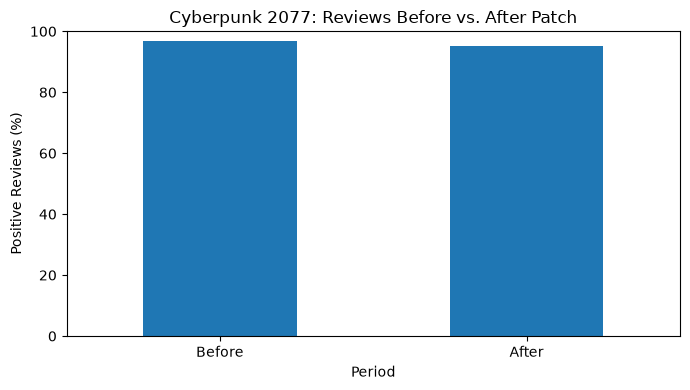

In [9]:
summary = summary.reindex(["Before", "After"])

summary["positive_percent"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title(f"{GAME}: Reviews Before vs. After Patch")
plt.ylabel("Positive Reviews (%)")
plt.xlabel("Period")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Multi-game analysis
Everything above is left as it was (single game: Cyberpunk 2077). The cells below reuse `get_json`, `get_patch_news` and `get_reviews` to run the same before/after comparison for **every game in `GAMES`**: Cyberpunk 2077, No Man's Sky, Helldivers 2 and Elden Ring.

Two improvements over the single-game run:
- **Official patch posts only.** The news feed also includes press articles (PC Gamer, GamingOnLinux, ...), so the single-game run picked a GamingOnLinux article as "the patch". Below, only the developer's own Steam announcements count, teasers ("is coming", "delayed", streams) are dropped, and posts within 3 days of each other are treated as one update.
- **Reviews spread across the whole 14-day window.** `get_reviews` returns newest reviews first, so 3 pages only covers the last few hours before the patch. Below, reviews are pulled one day at a time so every day of each window is sampled.

## 0. Added more games
Adds 16 games to `GAMES` (20 in total) so the before/after comparison covers more than the four case studies. The four originals stay in the list.

In [10]:
MORE_GAMES = {
    "Counter-Strike 2": 730,
    "Dota 2": 570,
    "Apex Legends": 1172470,
    "PUBG: BATTLEGROUNDS": 578080,
    "Rust": 252490,
    "Destiny 2": 1085660,
    "Warframe": 230410,
    "Dead by Daylight": 381210,
    "Marvel Rivals": 2767030,
    "Baldur's Gate 3": 1086940,
    "Terraria": 105600,
    "Stardew Valley": 413150,
    "Valheim": 892970,
    "Palworld": 1623730,
    "Lethal Company": 1966720,
    "Cities: Skylines II": 949230,
}

GAMES.update(MORE_GAMES)

GAME_TYPE = {g: "Case study" for g in ["Cyberpunk 2077", "No Man's Sky", "Helldivers 2", "Elden Ring"]}
GAME_TYPE.update({g: "Live-service" for g in list(MORE_GAMES)[:9]})
GAME_TYPE.update({g: "Content updates" for g in list(MORE_GAMES)[9:12]})
GAME_TYPE.update({g: "Early access" for g in list(MORE_GAMES)[12:]})

print(f"{len(GAMES)} games:", ", ".join(GAMES))

20 games: Cyberpunk 2077, No Man's Sky, Helldivers 2, Elden Ring, Counter-Strike 2, Dota 2, Apex Legends, PUBG: BATTLEGROUNDS, Rust, Destiny 2, Warframe, Dead by Daylight, Marvel Rivals, Baldur's Gate 3, Terraria, Stardew Valley, Valheim, Palworld, Lethal Company, Cities: Skylines II


In [11]:
# Every game gets its own case study now so the first four get sorted by update style like the rest
GAME_TYPE.update({
    "Helldivers 2": "Live-service",
    "Elden Ring": "Content updates",
    "Cyberpunk 2077": "Early access",
    "No Man's Sky": "Early access",
})
pd.Series(GAME_TYPE).value_counts()

Live-service       10
Early access        6
Content updates     4
Name: count, dtype: int64

In [12]:
# Make sure each app ID points to the right game before the long run
APPDETAILS_URL = "https://store.steampowered.com/api/appdetails"

for game, app_id in GAMES.items():
    try:
        data = get_json(APPDETAILS_URL, {"appids": app_id, "filters": "basic"})
        info = data.get(str(app_id), {})
        steam_name = info.get("data", {}).get("name") if info.get("success") else None
    except Exception as e:
        steam_name = f"ERROR: {e}"
    first_word = game.split()[0].strip(":").lower()
    flag = "" if steam_name and first_word in steam_name.lower() else "   <-- check this one"
    print(f"{app_id:>8}  {game:<22} Steam says: {steam_name}{flag}")
    time.sleep(1.5)

 1091500  Cyberpunk 2077         Steam says: Cyberpunk 2077
  275850  No Man's Sky           Steam says: No Man's Sky
  553850  Helldivers 2           Steam says: HELLDIVERS™ 2
 1245620  Elden Ring             Steam says: ELDEN RING
     730  Counter-Strike 2       Steam says: Counter-Strike 2
     570  Dota 2                 Steam says: Dota 2
 1172470  Apex Legends           Steam says: Apex Legends™
  578080  PUBG: BATTLEGROUNDS    Steam says: PUBG: BATTLEGROUNDS
  252490  Rust                   Steam says: Rust
 1085660  Destiny 2              Steam says: Destiny 2
  230410  Warframe               Steam says: Warframe
  381210  Dead by Daylight       Steam says: Dead by Daylight
 2767030  Marvel Rivals          Steam says: Marvel Rivals
 1086940  Baldur's Gate 3        Steam says: Baldur's Gate 3
  105600  Terraria               Steam says: Terraria
  413150  Stardew Valley         Steam says: Stardew Valley
  892970  Valheim                Steam says: Valheim
 1623730  Palworld   

In [13]:
PATCHES_PER_GAME = 3      # how many recent patches to check for each game
NEWS_PAGES = 5            # pages of news to pull per game (100 posts a page)
PAGES_PER_DAY = 1         # pages of reviews to pull for each day (100 reviews a page)
SAME_UPDATE_DAYS = 3      # posts this close together count as one update

TEASER_PATTERN = r"\b(?:coming|delayed|delay|preview|stream|redstreams|teaser|roadmap|sneak peek)\b"


def official_patches(news_df):
    """Keep only the dev's own patch posts and just one post per update."""
    if news_df.empty:
        return news_df

    df = news_df[news_df["is_patch_candidate"]].copy()

    # Only keep posts from the dev on Steam and skip news sites
    if "feedname" in df.columns:
        official = df[df["feedname"] == "steam_community_announcements"]
        if not official.empty:
            df = official

    # Skip posts that only tease or preview an update
    df = df[~df["title"].str.contains(TEASER_PATTERN, case=False, regex=True, na=False)]

    # If a few posts are about the same update keep the first one
    df = df.sort_values("date")
    gaps = df["date"].diff()
    df = df[gaps.isna() | (gaps > pd.Timedelta(days=SAME_UPDATE_DAYS))]

    return df.sort_values("date", ascending=False)

## 1. Collect news for every game

In [14]:
all_news = []

for game, app_id in GAMES.items():
    print(f"Collecting news for {game} ({app_id})...")
    try:
        news = get_patch_news(app_id, max_pages=NEWS_PAGES)
    except Exception as e:
        print("  failed:", e)
        continue
    news["game"] = game
    news["app_id"] = app_id
    all_news.append(news)
    print(f"  {len(news)} posts, {news['is_patch_candidate'].sum()} patch candidates")
    time.sleep(1.5)

all_news_df = pd.concat(all_news, ignore_index=True)
all_news_df.to_csv("all_games_news.csv", index=False)

/tmp/ipykernel_3411367/2810395493.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


  500 posts, 50 patch candidates


/tmp/ipykernel_3411367/2810395493.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


  500 posts, 168 patch candidates


/tmp/ipykernel_3411367/2810395493.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


  500 posts, 136 patch candidates


... (30 outputs left out)

/tmp/ipykernel_3411367/2810395493.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


  84 posts, 26 patch candidates


/tmp/ipykernel_3411367/2810395493.py:65: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["is_patch_candidate"] = df["title"].str.contains(


  213 posts, 49 patch candidates


## 2. Pick official patches for each game
Only patches with a full 14-day follow-up period are eligible. Check this table by hand and edit it if a post isn't really a patch.

In [15]:
cutoff = pd.Timestamp.now(tz="UTC") - pd.Timedelta(days=WINDOW_DAYS)

selected = []
for game, news in all_news_df.groupby("game"):
    patches = official_patches(news)
    patches = patches[patches["date"] < cutoff].head(PATCHES_PER_GAME)
    selected.append(patches)

selected_patches = pd.concat(selected, ignore_index=True)
selected_patches = selected_patches.sort_values(["game", "date"])

display(selected_patches[["game", "date", "title", "url"]])

,game,date,title,url
2,Apex Legends,2026-10-20 18:05:45+00:00,Apex Legends: Latest Update 10/20/2026,https://steamstore-a.akamaihd.net/news/externa...
1,Apex Legends,2026-10-28 02:00:32+00:00,Apex Legends: Latest Update - 10/26/2026,https://steamstore-a.akamaihd.net/news/externa...
0,Apex Legends,2026-11-02 18:58:53+00:00,Apex Legends™: Cipher Patch Notes,https://steamstore-a.akamaihd.net/news/externa...
5,Baldur's Gate 3,2025-11-20 13:24:05+00:00,Hotfix #35 Now Live!,https://steamstore-a.akamaihd.net/news/externa...
4,Baldur's Gate 3,2025-12-01 16:12:32+00:00,Community Update #36 A Very Moddy Christmas,https://steamstore-a.akamaihd.net/news/externa...
3,Baldur's Gate 3,2026-03-26 14:40:05+00:00,Hotfix #36 Now Live!,https://steamstore-a.akamaihd.net/news/externa...
8,Cities: Skylines II,2026-05-27 08:00:37+00:00,Patch 1.5.9f1 - Morning Dew,https://steamstore-a.akamaihd.net/news/externa...
7,Cities: Skylines II,2026-06-22 12:00:56+00:00,Patch 1.6.0f1 - Summer Solstice,https://steamstore-a.akamaihd.net/news/externa...
6,Cities: Skylines II,2026-09-15 16:14:17+00:00,Patch 1.6.2f1 - Autumn Breeze,https://steamstore-a.akamaihd.net/news/externa...
11,Counter-Strike 2,2026-10-22 22:56:10+00:00,Counter-Strike 2 Update,https://steamstore-a.akamaihd.net/news/externa...


## 3. Collect reviews before and after each patch
One request batch per day of each window, so all 14 days on each side are sampled. With the defaults this is about 28 requests per patch, so expect several minutes in total.

In [16]:
def get_reviews_by_day(app_id, start, end, pages_per_day=1):
    """Pull reviews one day at a time so we get every day in the window."""
    days = []
    day_start = start
    while day_start < end:
        day_end = min(day_start + pd.Timedelta(days=1), end) - pd.Timedelta(seconds=1)
        day = get_reviews(app_id, day_start, day_end, max_pages=pages_per_day)
        if not day.empty:
            days.append(day)
        day_start = day_start + pd.Timedelta(days=1)
        time.sleep(1.5)
    return pd.concat(days, ignore_index=True) if days else pd.DataFrame()


all_reviews = []

for _, patch in selected_patches.iterrows():
    game, app_id, p_date = patch["game"], patch["app_id"], patch["date"]
    print(f"\n=== {game}: {patch['title']} ({p_date.date()}) ===")

    try:
        before = get_reviews_by_day(app_id, p_date - pd.Timedelta(days=WINDOW_DAYS),
                                    p_date, PAGES_PER_DAY)
        after = get_reviews_by_day(app_id, p_date,
                                   p_date + pd.Timedelta(days=WINDOW_DAYS), PAGES_PER_DAY)
    except Exception as e:
        print("  failed:", e)
        continue

    for part, label in [(before, "Before"), (after, "After")]:
        if part.empty:
            continue
        part["period"] = label
        part["game"] = game
        part["app_id"] = app_id
        part["patch_title"] = patch["title"]
        part["patch_date"] = p_date
        all_reviews.append(part)

all_reviews_df = pd.concat(all_reviews, ignore_index=True)
all_reviews_df = all_reviews_df.drop_duplicates(subset=["review_id", "patch_date"])
all_reviews_df.to_csv("all_games_patch_reviews.csv", index=False)

print(f"\nTotal reviews collected: {len(all_reviews_df)}")


=== Apex Legends: Apex Legends: Latest Update 10/20/2026 (2026-10-20) ===
Page 1: 86 reviews collected
Page 1: 74 reviews collected
Page 1: 66 reviews collected
Page 1: 84 reviews collected
Page 1: 71 reviews collected
Page 1: 62 reviews collected
Page 1: 55 reviews collected
Page 1: 60 reviews collected
Page 1: 71 reviews collected
Page 1: 55 reviews collected
Page 1: 61 reviews collected
Page 1: 84 reviews collected
Page 1: 61 reviews collected
Page 1: 43 reviews collected
Page 1: 56 reviews collected
Page 1: 73 reviews collected
Page 1: 74 reviews collected
Page 1: 70 reviews collected
Page 1: 64 reviews collected
Page 1: 54 reviews collected
Page 1: 60 reviews collected
Page 1: 60 reviews collected
Page 1: 51 reviews collected
Page 1: 53 reviews collected
Page 1: 50 reviews collected
Page 1: 65 reviews collected
Page 1: 48 reviews collected
Page 1: 88 reviews collected

=== Apex Legends: Apex Legends: Latest Update - 10/26/2026 (2026-10-28) ===
Page 1: 66 reviews collected
Page 1:

## 4. Before vs. after for every patch

In [17]:
patch_summary = (
    all_reviews_df
    .groupby(["game", "patch_date", "patch_title", "period"])["positive"]
    .agg(reviews="count", positive_percent=lambda s: s.mean() * 100)
    .unstack("period")
)
patch_summary.columns = [f"{stat}_{period.lower()}" for stat, period in patch_summary.columns]
patch_summary["change_points"] = (
    patch_summary["positive_percent_after"] - patch_summary["positive_percent_before"]
)
patch_summary = patch_summary.reset_index().sort_values(["game", "patch_date"])

display(patch_summary.round({c: 1 for c in patch_summary.select_dtypes("number").columns}))
patch_summary.to_csv("all_games_patch_summary.csv", index=False)

,game,patch_date,patch_title,reviews_after,reviews_before,positive_percent_after,positive_percent_before,change_points
0,Apex Legends,2026-10-20 18:05:45+00:00,Apex Legends: Latest Update 10/20/2026,866,933,71.2,67.4,3.8
1,Apex Legends,2026-10-28 02:00:32+00:00,Apex Legends: Latest Update - 10/26/2026,876,877,70.8,71.4,-0.6
2,Apex Legends,2026-11-02 18:58:53+00:00,Apex Legends™: Cipher Patch Notes,942,822,70.2,71.3,-1.1
3,Baldur's Gate 3,2025-11-20 13:24:05+00:00,Hotfix #35 Now Live!,1367,1311,97.3,96.0,1.3
4,Baldur's Gate 3,2025-12-01 16:12:32+00:00,Community Update #36 A Very Moddy Christmas,1287,1366,95.1,97.5,-2.4
5,Baldur's Gate 3,2026-03-26 14:40:05+00:00,Hotfix #36 Now Live!,1254,1269,95.3,95.7,-0.4
6,Cities: Skylines II,2026-05-27 08:00:37+00:00,Patch 1.5.9f1 - Morning Dew,233,238,79.8,71.8,8.0
7,Cities: Skylines II,2026-06-22 12:00:56+00:00,Patch 1.6.0f1 - Summer Solstice,319,266,75.9,77.4,-1.6
8,Cities: Skylines II,2026-09-15 16:14:17+00:00,Patch 1.6.2f1 - Autumn Breeze,578,236,42.9,68.6,-25.7
9,Counter-Strike 2,2026-10-22 22:56:10+00:00,Counter-Strike 2 Update,1400,1400,75.9,76.7,-0.9


In [18]:
# Average change for each game
game_summary = patch_summary.groupby("game").agg(
    patches=("patch_title", "count"),
    avg_before=("positive_percent_before", "mean"),
    avg_after=("positive_percent_after", "mean"),
    avg_change=("change_points", "mean"),
    patches_that_helped=("change_points", lambda s: (s > 0).sum()),
)
display(game_summary.round(1))

,patches,avg_before,avg_after,avg_change,patches_that_helped
game,,,,,
Apex Legends,3,70.0,70.7,0.7,1
Baldur's Gate 3,3,96.4,95.9,-0.5,1
Cities: Skylines II,3,72.6,66.2,-6.4,1
Counter-Strike 2,3,76.8,78.5,1.7,2
Cyberpunk 2077,3,95.5,94.6,-1.0,0
Dead by Daylight,3,63.5,57.5,-6.1,1
Destiny 2,3,76.2,71.8,-4.3,0
Dota 2,3,76.4,73.8,-2.5,0
Elden Ring,3,94.5,90.3,-4.2,1


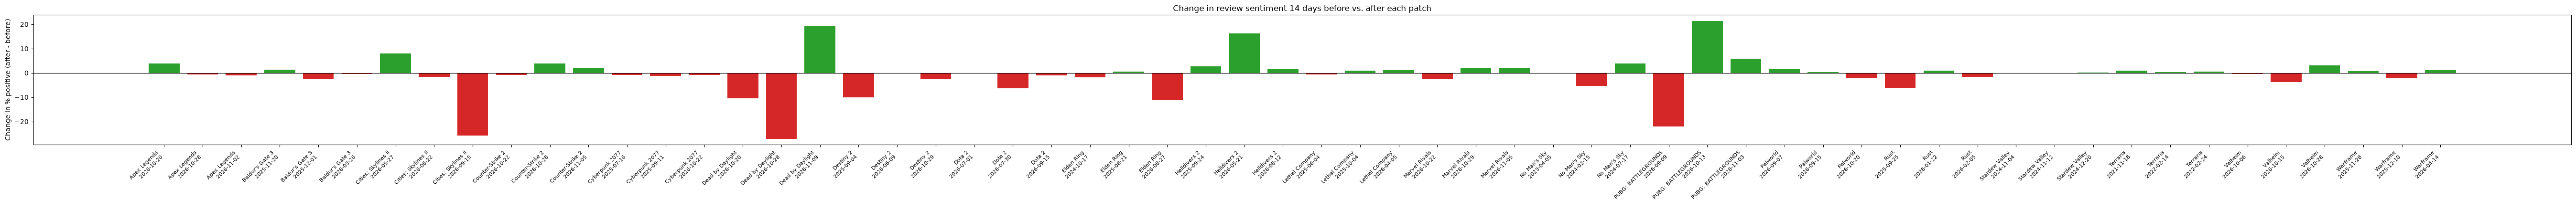

In [19]:
# Bar chart of how much each patch moved the reviews
plot_df = patch_summary.copy()
plot_df["label"] = plot_df["game"] + "\n" + plot_df["patch_date"].dt.strftime("%Y-%m-%d")
colors = ["tab:green" if c > 0 else "tab:red" for c in plot_df["change_points"]]

fig, ax = plt.subplots(figsize=(max(8, len(plot_df) * 0.9), 4.5))
ax.bar(plot_df["label"], plot_df["change_points"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Change in % positive (after - before)")
ax.set_title(f"Change in review sentiment {WINDOW_DAYS} days before vs. after each patch")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

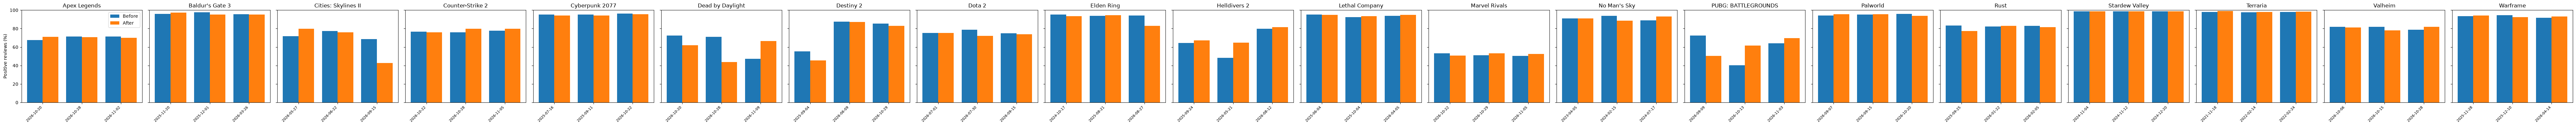

In [20]:
# Before and after bars for each game's patches
games_list = list(patch_summary["game"].unique())
fig, axes = plt.subplots(1, len(games_list), figsize=(4 * len(games_list), 4), sharey=True)
if len(games_list) == 1:
    axes = [axes]

for ax, game in zip(axes, games_list):
    g = patch_summary[patch_summary["game"] == game]
    x = range(len(g))
    ax.bar([i - 0.2 for i in x], g["positive_percent_before"], width=0.4, label="Before")
    ax.bar([i + 0.2 for i in x], g["positive_percent_after"], width=0.4, label="After")
    ax.set_xticks(list(x))
    ax.set_xticklabels(g["patch_date"].dt.strftime("%Y-%m-%d"), rotation=45, ha="right", fontsize=8)
    ax.set_title(game)
    ax.set_ylim(0, 100)

axes[0].set_ylabel("Positive reviews (%)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 5. Long-term review history for every game
Steam's review histogram gives up/down review counts per month (or week) over each game's whole life in one request per game: the same data behind the review graph on the store page. This shows the long-term trend, with every official patch marked, without downloading every review.

In [21]:
HISTOGRAM_URL = "https://store.steampowered.com/appreviewhistogram/{}"


def get_review_history(app_id):
    data = get_json(HISTOGRAM_URL.format(app_id), {"l": "english"})
    results = data.get("results") or {}
    df = pd.DataFrame(results.get("rollups", []))
    if df.empty:
        return df
    df = df.rename(columns={"recommendations_up": "up", "recommendations_down": "down"})
    df["date"] = pd.to_datetime(df["date"], unit="s", utc=True)
    df["granularity"] = results.get("rollup_type")
    df["positive_percent"] = df["up"] / (df["up"] + df["down"]) * 100
    return df


history = []
for game, app_id in GAMES.items():
    print(f"Review history for {game}...")
    try:
        h = get_review_history(app_id)
    except Exception as e:
        print("  failed:", e)
        continue
    h["game"] = game
    history.append(h)
    time.sleep(1.5)

history_df = pd.concat(history, ignore_index=True)
history_df.to_csv("all_games_review_history.csv", index=False)
display(history_df.groupby("game").agg(
    periods=("date", "count"), granularity=("granularity", "first"),
    first=("date", "min"), last=("date", "max"),
    total_reviews=("up", lambda s: s.sum() + history_df.loc[s.index, "down"].sum()),
))

Review history for Cyberpunk 2077...
Review history for No Man's Sky...
Review history for Helldivers 2...
Review history for Elden Ring...
Review history for Counter-Strike 2...
Review history for Dota 2...
Review history for Apex Legends...
Review history for PUBG: BATTLEGROUNDS...
Review history for Rust...
Review history for Destiny 2...
Review history for Warframe...
Review history for Dead by Daylight...
Review history for Marvel Rivals...
Review history for Baldur's Gate 3...
Review history for Terraria...
Review history for Stardew Valley...
Review history for Valheim...
Review history for Palworld...
Review history for Lethal Company...
Review history for Cities: Skylines II...


,periods,granularity,first,last,total_reviews
game,,,,,
Apex Legends,73,month,2020-11-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,1180448
Baldur's Gate 3,74,month,2020-10-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,789657
Cities: Skylines II,38,month,2023-10-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,70087
Counter-Strike 2,173,month,2012-05-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,10780443
Cyberpunk 2077,72,month,2020-12-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,974080
Dead by Daylight,126,month,2016-06-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,769579
Destiny 2,86,month,2019-10-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,716961
Dota 2,184,month,2011-08-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,3042036
Elden Ring,58,month,2022-02-01 00:00:00+00:00,2026-11-01 00:00:00+00:00,888768


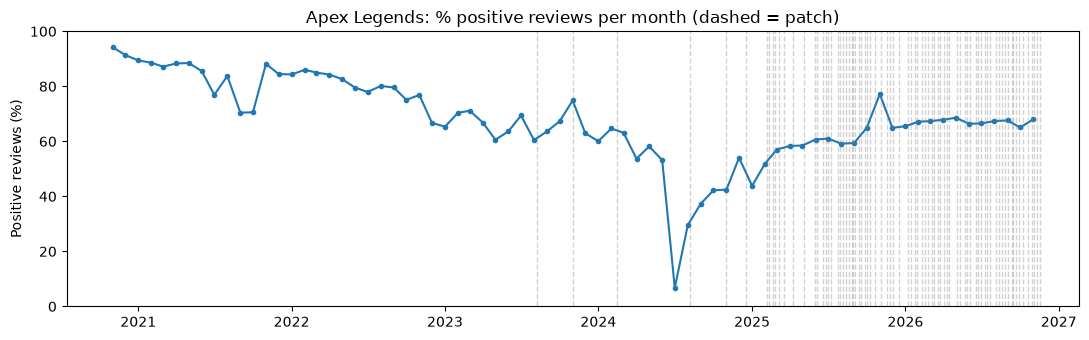

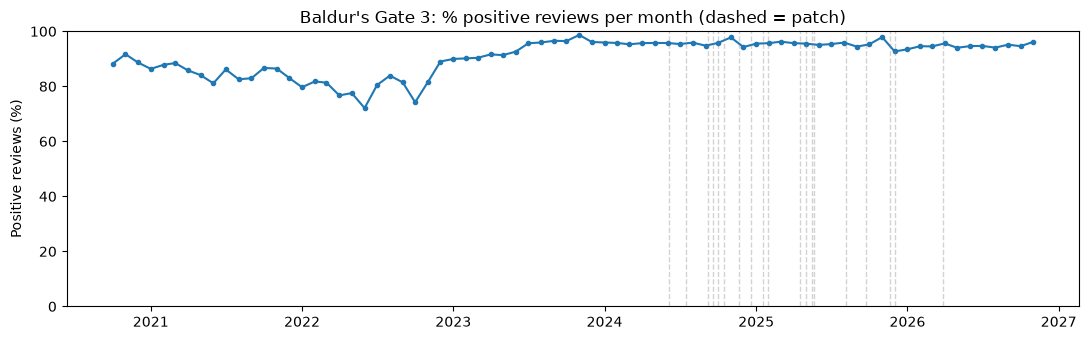

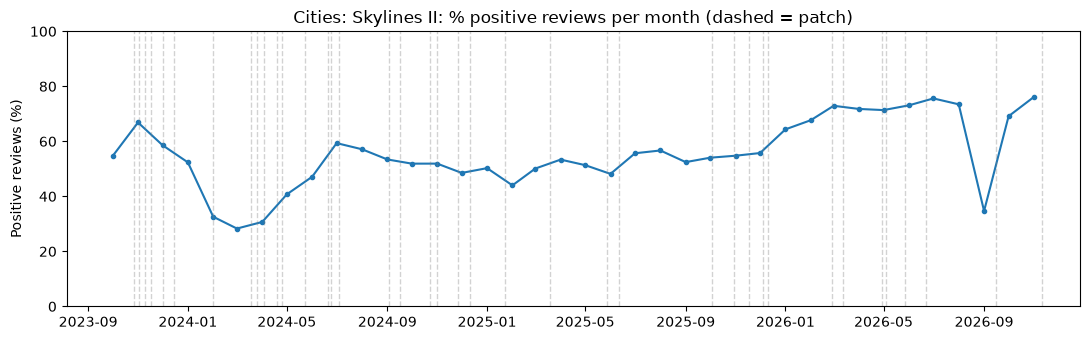

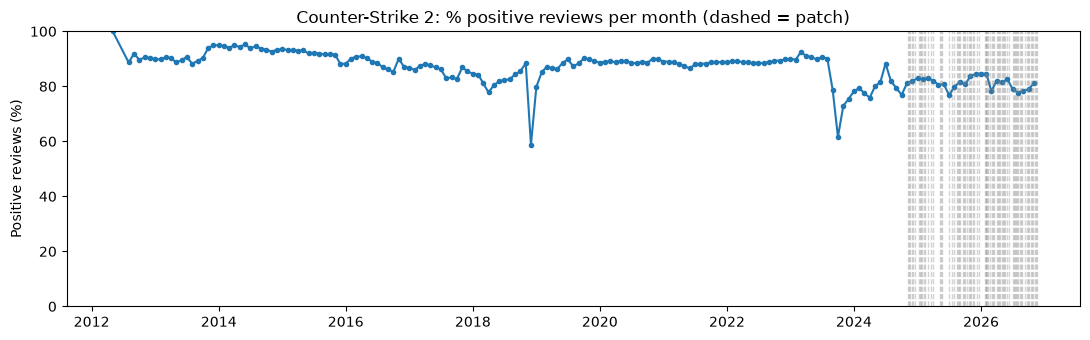

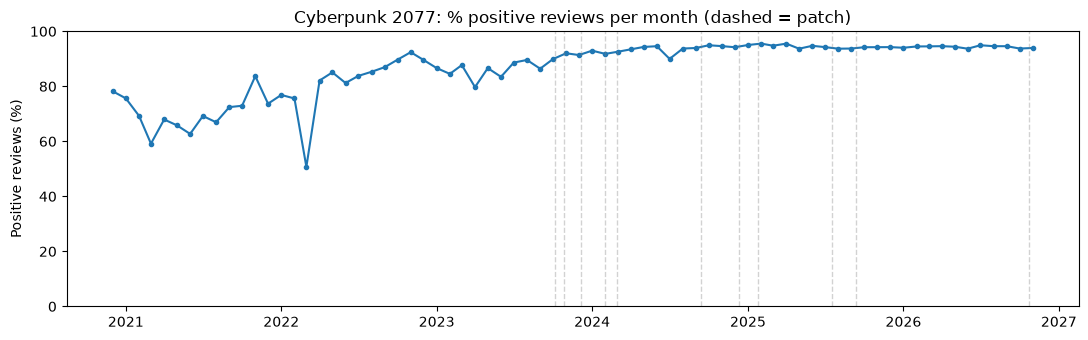

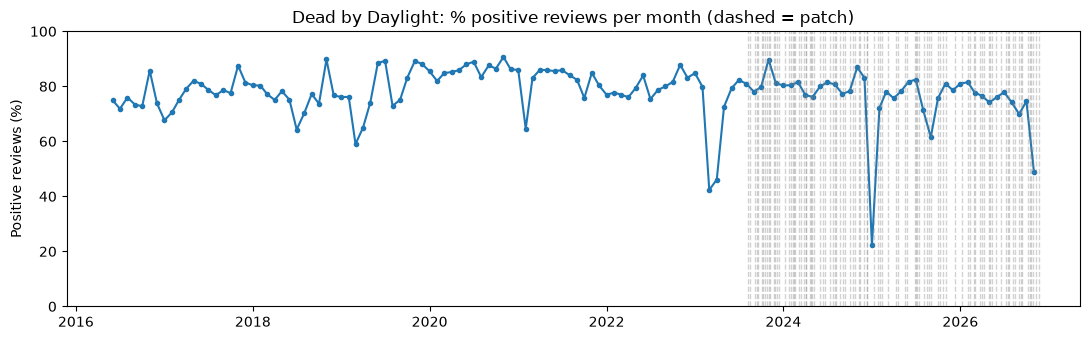

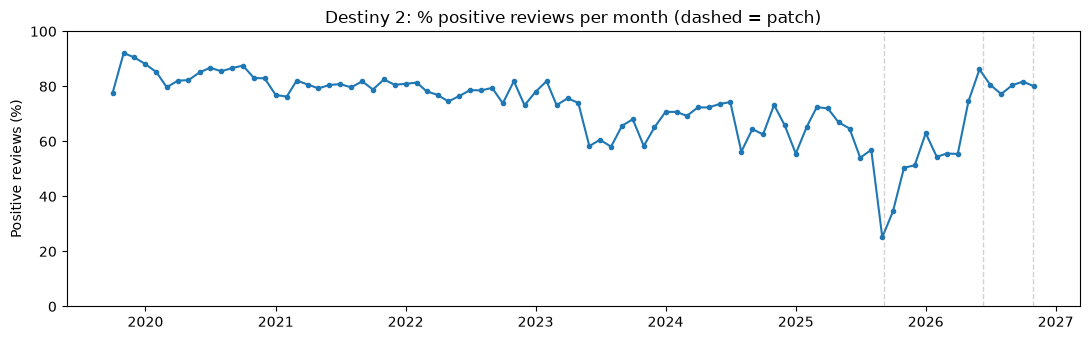

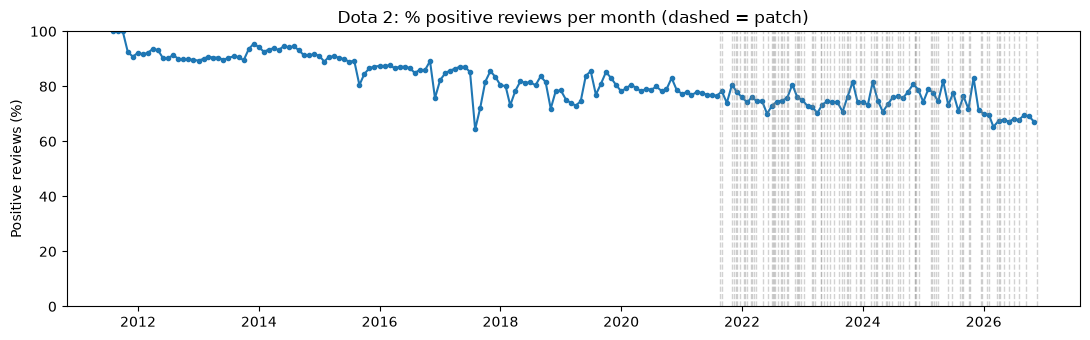

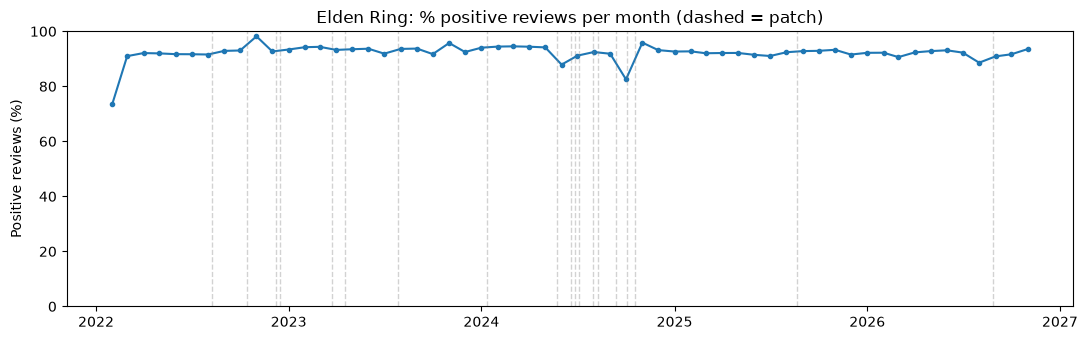

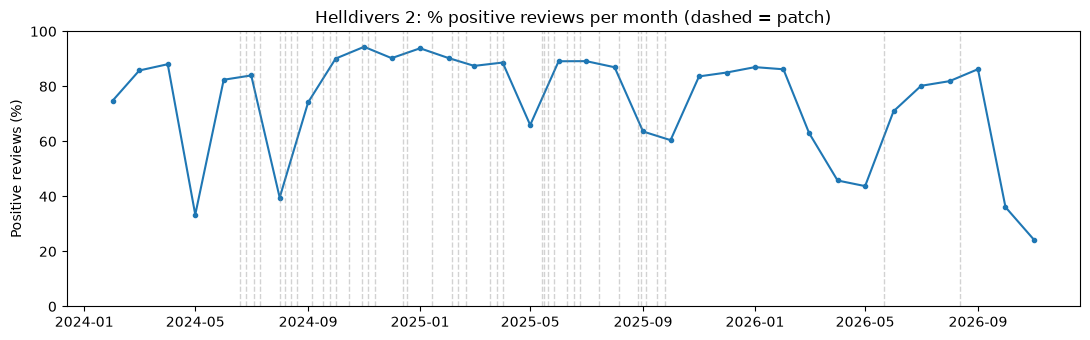

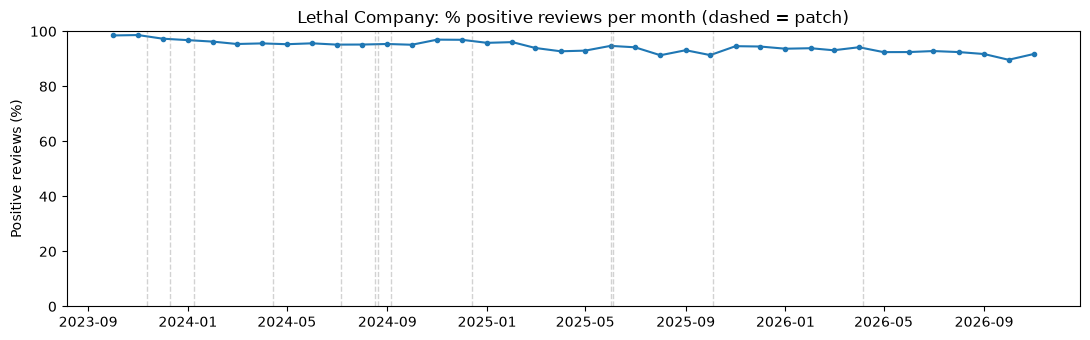

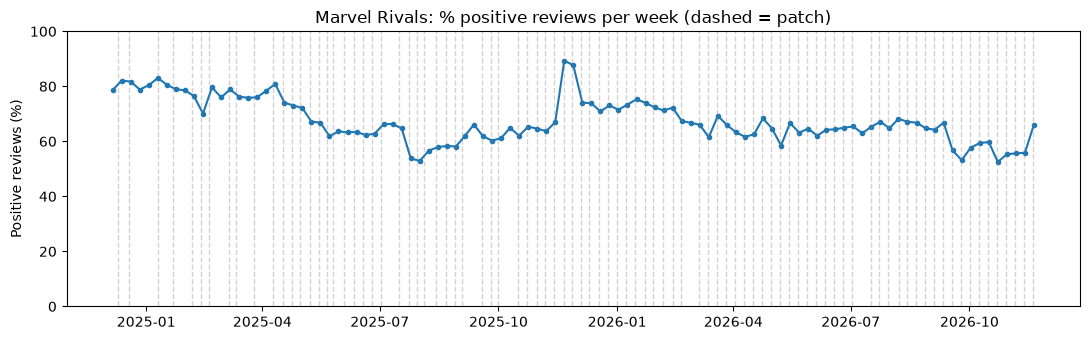

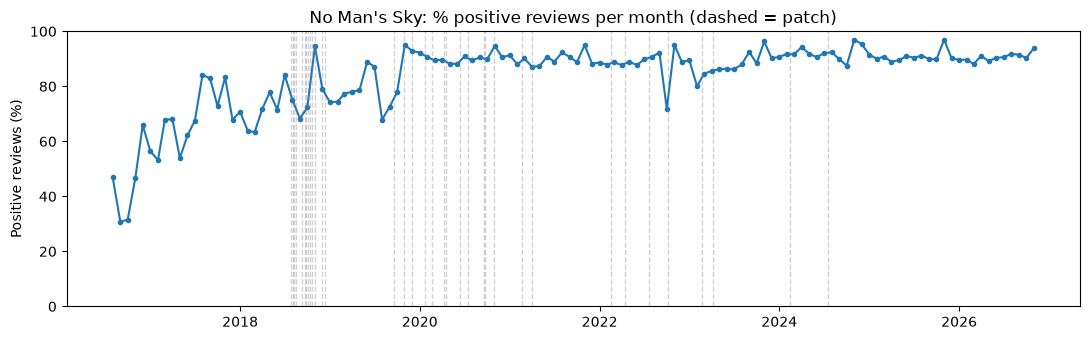

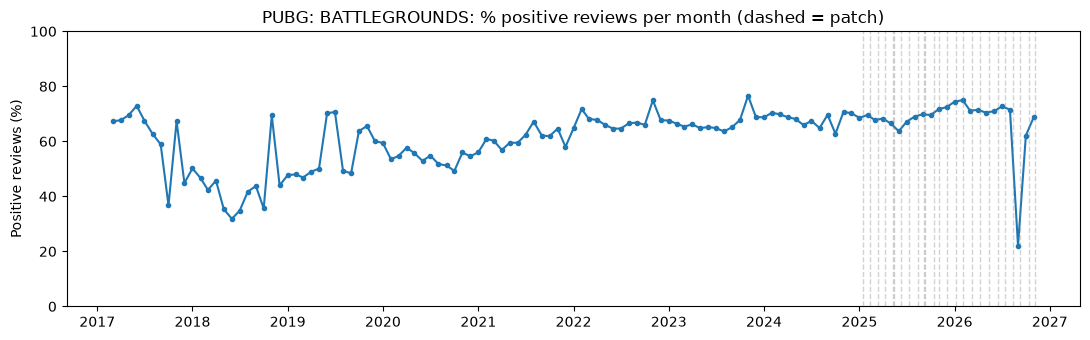

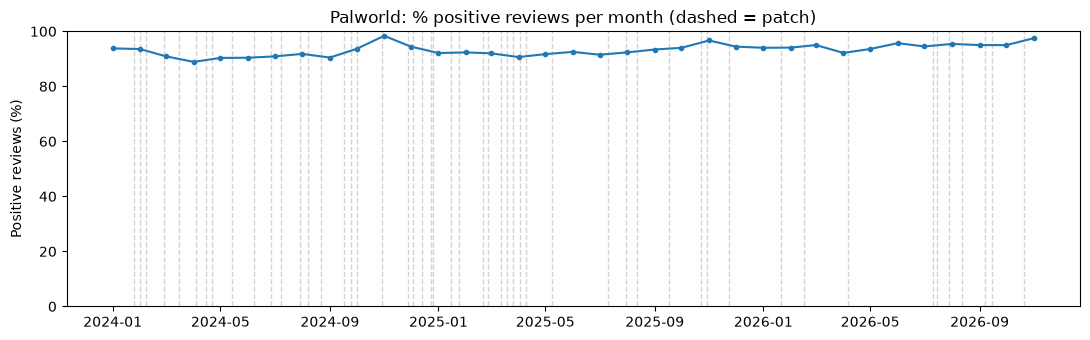

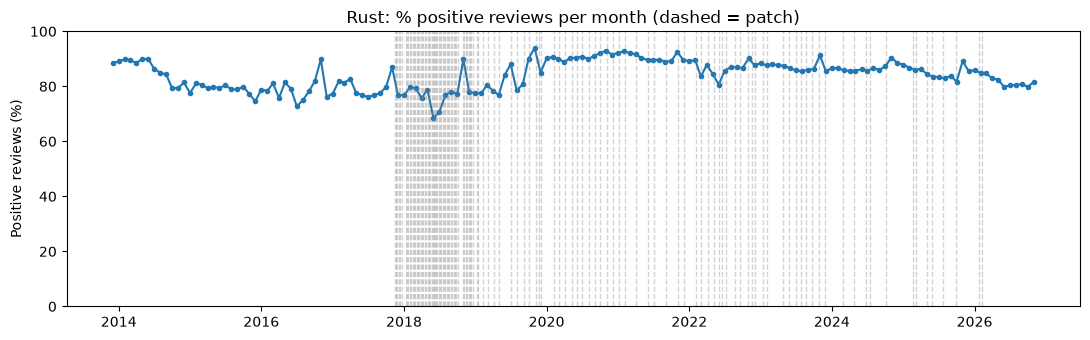

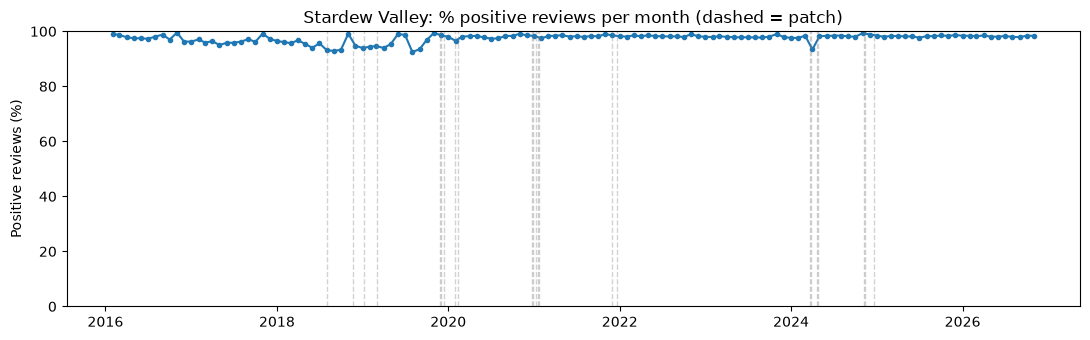

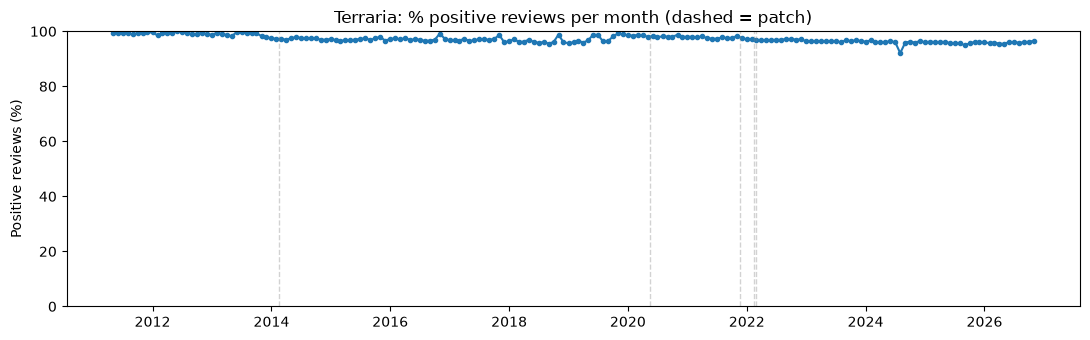

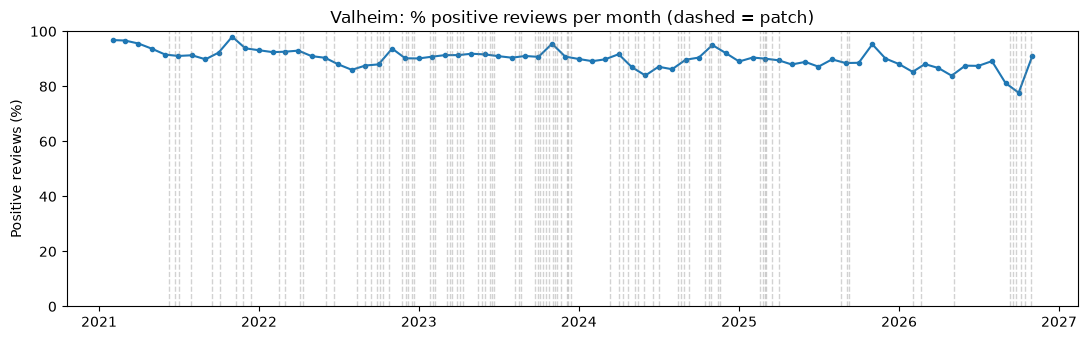

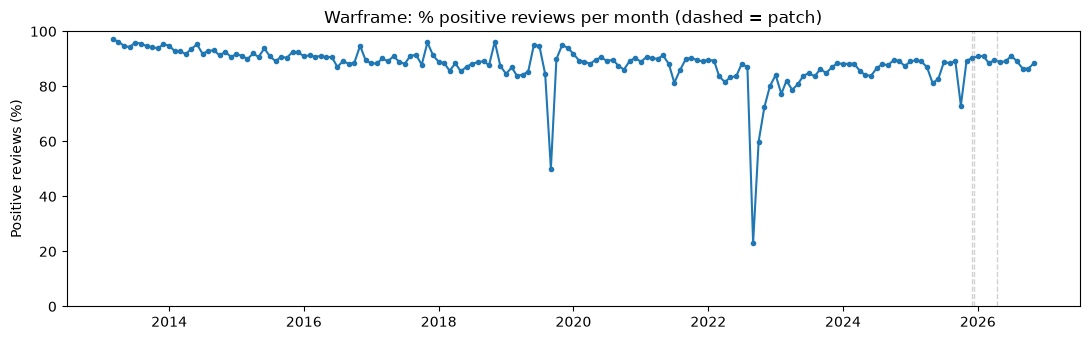

In [22]:
# Line chart of reviews over time for each game with patches as dashed lines
for game, h in history_df.groupby("game"):
    h = h.sort_values("date")
    fig, ax = plt.subplots(figsize=(11, 3.5))
    ax.plot(h["date"], h["positive_percent"], marker="o", markersize=3)

    official = official_patches(all_news_df[all_news_df["game"] == game])
    for d in official["date"]:
        ax.axvline(d, color="gray", linestyle="--", alpha=0.35, linewidth=1)

    ax.set_title(f"{game}: % positive reviews per {h['granularity'].iloc[0]} (dashed = patch)")
    ax.set_ylabel("Positive reviews (%)")
    ax.set_ylim(0, 100)
    plt.tight_layout()
    plt.show()

## 6. Results across all games
With 20 games the per-game side-by-side chart above gets very wide; these views scale better.

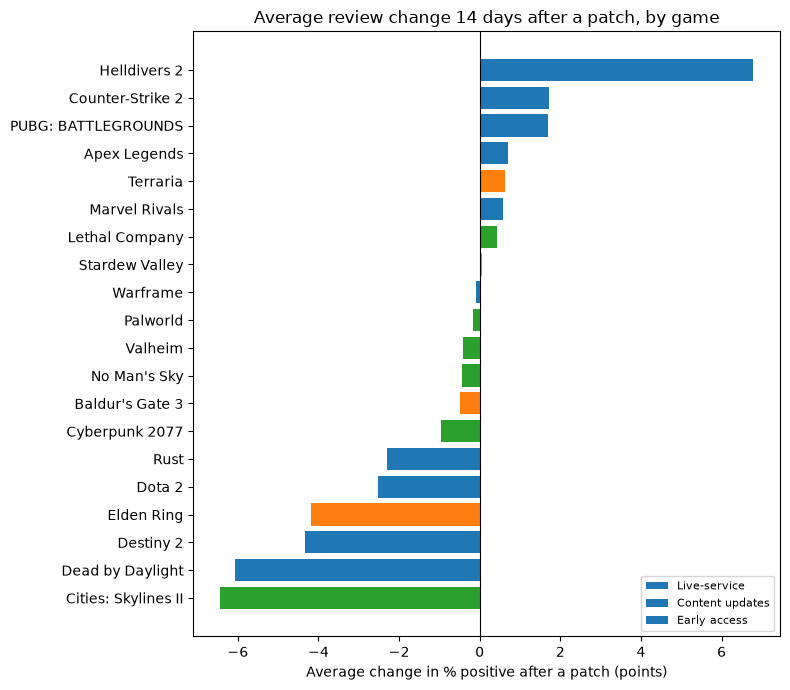

In [23]:
# Average change for each game sorted and colored by type
per_game = patch_summary.groupby("game").agg(
    patches=("change_points", "count"),
    avg_change=("change_points", "mean"),
).reset_index()
per_game["type"] = per_game["game"].map(GAME_TYPE).fillna("Other")
per_game = per_game.sort_values("avg_change")

type_colors = {"Case study": "tab:purple", "Live-service": "tab:blue",
               "Content updates": "tab:orange", "Early access": "tab:green", "Other": "tab:gray"}

fig, ax = plt.subplots(figsize=(8, max(4, len(per_game) * 0.35)))
ax.barh(per_game["game"], per_game["avg_change"],
        color=[type_colors[t] for t in per_game["type"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Average change in % positive after a patch (points)")
ax.set_title(f"Average review change {WINDOW_DAYS} days after a patch, by game")
for t, c in type_colors.items():
    if t in set(per_game["type"]):
        ax.barh([], [], color=c, label=t)
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

In [24]:
# Results for each type of game
patch_summary["type"] = patch_summary["game"].map(GAME_TYPE).fillna("Other")
by_type = patch_summary.groupby("type").agg(
    games=("game", "nunique"),
    patches=("change_points", "count"),
    avg_change=("change_points", "mean"),
    share_that_helped=("change_points", lambda s: (s > 0).mean() * 100),
)
display(by_type.round(1))

,games,patches,avg_change,share_that_helped
type,,,,
Content updates,4,12,-1.0,58.3
Early access,6,18,-1.3,44.4
Live-service,10,30,-0.4,46.7


In [25]:
# Did patches change reviews on average?
# We resample the patches a bunch of times to get a 95% range for the average
import numpy as np

changes = patch_summary["change_points"].dropna().to_numpy()
rng = np.random.default_rng(0)
boot = [rng.choice(changes, size=len(changes), replace=True).mean() for _ in range(5000)]
low, high = np.percentile(boot, [2.5, 97.5])

print(f"Patches analyzed: {len(changes)} across {patch_summary['game'].nunique()} games")
print(f"Average change in % positive: {changes.mean():+.1f} points")
print(f"95% confidence interval: {low:+.1f} to {high:+.1f} points")
print(f"Patches followed by an improvement: {(changes > 0).mean() * 100:.0f}%")
if low > 0:
    print("-> Reviews were reliably MORE positive after patches.")
elif high < 0:
    print("-> Reviews were reliably LESS positive after patches.")
else:
    print("-> No reliable overall change: the interval includes zero.")

Patches analyzed: 60 across 20 games
Average change in % positive: -0.8 points
95% confidence interval: -2.8 to +1.1 points
Patches followed by an improvement: 48%
-> No reliable overall change: the interval includes zero.


## 7. Case study for every game
Each case study shows:
1. The official patches analyzed and the before/after review numbers for each
2. A chart: before vs. after per patch, next to the game's long-term review history with patches marked
3. Who was reviewing: number of reviews, median playtime, and review length before vs. after
4. What players talked about: words that show up much more in negative reviews after a patch than before
5. A one-paragraph written summary

Charts are also saved to a `case_studies/` folder for your report, and a one-row-per-game summary is saved to `case_studies_summary.csv`.

In [26]:
import os
import numpy as np
from collections import Counter

try:
    from IPython.display import Markdown
except ImportError:
    Markdown = str

os.makedirs("case_studies", exist_ok=True)

STOPWORDS = set("""
a about above after again all also am an and any are as at be because been before being
but by can could did do does doing don dont down during each even few for from get got
had has have having he her here him his how i if in into is it its it's itself just like
me more most much my no nor not now of off on once only or other our out over own really
same she should so some still such than that the their them then there these they this
those through to too under until up very was we were what when where which while who why
will with would you your i'm i've you're can't won't didn't doesn't isn't wasn't
game games play playing played one make time good great fun get even well way thing things
lot new still back see go going first many every much
""".split())


def words(texts):
    counts = Counter()
    for t in texts.dropna():
        counts.update(w for w in re.findall(r"[a-z][a-z']{2,}", t.lower())
                      if w not in STOPWORDS)
    return counts


def rising_words(after_texts, before_texts, n=10, min_count=3):
    """Find words used a lot more after the patch than before."""
    a, b = words(after_texts), words(before_texts)
    total_a, total_b = sum(a.values()) or 1, sum(b.values()) or 1
    vocab = len(set(a) | set(b)) or 1
    scored = [
        (w, np.log((a[w] + 1) / (total_a + vocab)) - np.log((b[w] + 1) / (total_b + vocab)), a[w], b[w])
        for w in a if a[w] >= min_count
    ]
    scored = [x for x in scored if x[1] > 0]  # only keep words that went up
    scored.sort(key=lambda x: x[1], reverse=True)
    return [(w, ca, cb) for w, _, ca, cb in scored[:n]]


def safe_name(name):
    return re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")

In [27]:
def case_study(game):
    app_id = GAMES[game]
    gtype = GAME_TYPE.get(game, "Other")
    display(Markdown(f"---\n### {game}  \n*Steam app {app_id} · {gtype}*"))

    ps = patch_summary[patch_summary["game"] == game].sort_values("patch_date")
    rv = all_reviews_df[all_reviews_df["game"] == game]
    hist = history_df[history_df["game"] == game].sort_values("date") if "history_df" in globals() else pd.DataFrame()

    if ps.empty:
        print("No patches with review data for this game: nothing to analyze.")
        return None

    # 1. List the patches with before and after numbers
    table = ps[["patch_date", "patch_title", "reviews_before", "reviews_after",
                "positive_percent_before", "positive_percent_after", "change_points"]].copy()
    table["patch_date"] = table["patch_date"].dt.strftime("%Y-%m-%d")
    display(table.round(1).reset_index(drop=True))

    # 2. Make the charts
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4),
                                   gridspec_kw={"width_ratios": [1, 2]})
    x = np.arange(len(ps))
    ax1.bar(x - 0.2, ps["positive_percent_before"], width=0.4, label="Before")
    ax1.bar(x + 0.2, ps["positive_percent_after"], width=0.4, label="After")
    ax1.set_xticks(x)
    ax1.set_xticklabels(ps["patch_date"].dt.strftime("%Y-%m-%d"), rotation=30, ha="right", fontsize=8)
    ax1.set_ylim(0, 100)
    ax1.set_ylabel("Positive reviews (%)")
    ax1.set_title(f"{WINDOW_DAYS} days before vs. after each patch")
    ax1.legend(fontsize=8, loc="lower right")

    if not hist.empty:
        ax2.plot(hist["date"], hist["positive_percent"], marker="o", markersize=2)
        official = official_patches(all_news_df[all_news_df["game"] == game])
        for d in official["date"]:
            ax2.axvline(d, color="gray", linestyle="--", alpha=0.25, linewidth=1)
        for d in ps["patch_date"]:
            ax2.axvline(d, color="red", alpha=0.7, linewidth=1.2)
        ax2.set_ylim(0, 100)
        ax2.set_title(f"Review history per {hist['granularity'].iloc[0]} "
                      "(red = patches analyzed, gray = other patches)")
    else:
        ax2.text(0.5, 0.5, "No review history collected", ha="center", va="center")
        ax2.set_axis_off()

    fig.suptitle(game, fontweight="bold")
    plt.tight_layout()
    fig.savefig(f"case_studies/{safe_name(game)}.png", dpi=150, bbox_inches="tight")
    plt.show()

    # 3. See who was writing reviews
    who = rv.assign(review_length=rv["review_text"].fillna("").str.split().str.len()).groupby("period").agg(
        reviews=("positive", "count"),
        positive_percent=("positive", lambda s: s.mean() * 100),
        median_playtime_hours=("playtime_hours", "median"),
        median_review_words=("review_length", "median"),
    ).reindex(["Before", "After"])
    display(who.round(1))

    # 4. Find what people complained about in bad reviews
    neg = rv[rv["positive"] == False]
    rising = rising_words(neg.loc[neg["period"] == "After", "review_text"],
                          neg.loc[neg["period"] == "Before", "review_text"])
    if rising:
        display(pd.DataFrame(rising, columns=["word", "times_after", "times_before"]))
    else:
        print("Too few negative reviews to compare wording.")

    # 5. Write a short summary
    best, worst = ps.loc[ps["change_points"].idxmax()], ps.loc[ps["change_points"].idxmin()]
    avg = ps["change_points"].mean()
    direction = "rose" if avg > 0.5 else "fell" if avg < -0.5 else "stayed about the same"
    text = (
        f"**Summary:** Across {len(ps)} patch(es), positive reviews {direction} after updates "
        f"(average change {avg:+.1f} points, from {ps['positive_percent_before'].mean():.1f}% "
        f"to {ps['positive_percent_after'].mean():.1f}%). "
        f"Best reaction: *{best['patch_title']}* ({best['patch_date']:%Y-%m-%d}, {best['change_points']:+.1f}). "
        f"Worst reaction: *{worst['patch_title']}* ({worst['patch_date']:%Y-%m-%d}, {worst['change_points']:+.1f})."
    )
    if rising:
        text += " Words rising in negative reviews after patches: " + ", ".join(w for w, _, _ in rising[:5]) + "."
    display(Markdown(text))

    return {
        "game": game, "app_id": app_id, "type": gtype, "patches": len(ps),
        "avg_before": ps["positive_percent_before"].mean(),
        "avg_after": ps["positive_percent_after"].mean(),
        "avg_change": avg,
        "best_patch": best["patch_title"], "best_change": best["change_points"],
        "worst_patch": worst["patch_title"], "worst_change": worst["change_points"],
        "median_playtime_before": who.loc["Before", "median_playtime_hours"],
        "median_playtime_after": who.loc["After", "median_playtime_hours"],
        "rising_negative_words": ", ".join(w for w, _, _ in rising[:5]),
    }

---
### Cyberpunk 2077  
*Steam app 1091500 · Early access*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2025-07-16,Update 2.3 Patch Notes,1400,1400,95.1,94.2,-0.9
1,2025-09-11,Patch 2.31,1391,1363,95.3,94.1,-1.3
2,2026-10-22,Cyberpunk 2077's Edgerunners 2 Update (2.5) is...,1400,1400,96.2,95.4,-0.8


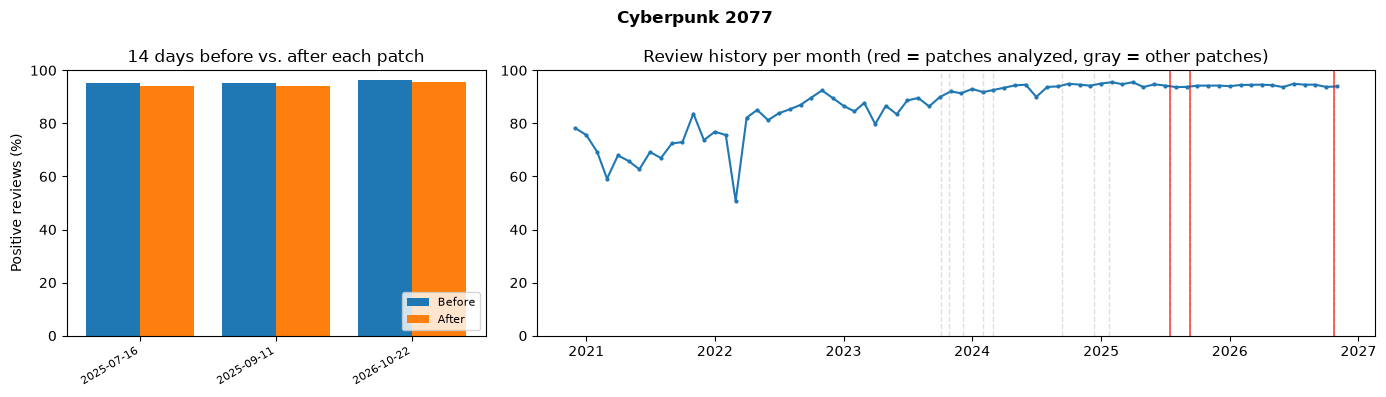

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,4191,95.5,57.5,8.0
After,4163,94.6,62.7,7.0


,word,times_after,times_before
0,eula,10,0
1,longer,6,0
2,broke,6,0
3,saves,6,0
4,edgerunners,6,0
5,arbitration,5,0
6,terms,5,0
7,ruined,5,0
8,ending,5,0
9,previous,5,0


**Summary:** Across 3 patch(es), positive reviews fell after updates (average change -1.0 points, from 95.5% to 94.6%). Best reaction: *Cyberpunk 2077's Edgerunners 2 Update (2.5) is out now!* (2026-10-22, -0.8). Worst reaction: *Patch 2.31* (2025-09-11, -1.3). Words rising in negative reviews after patches: eula, longer, broke, saves, edgerunners.

---
### No Man's Sky  
*Steam app 275850 · Early access*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2023-04-05,Introducing...the INTERCEPTOR Update,385,988,91.2,91.2,0.0
1,2024-02-15,Introducing..the OMEGA update!,299,779,94.0,88.7,-5.3
2,2024-07-17,Introducing Worlds Part I - the 5.0 update,339,1400,89.1,93.0,3.9


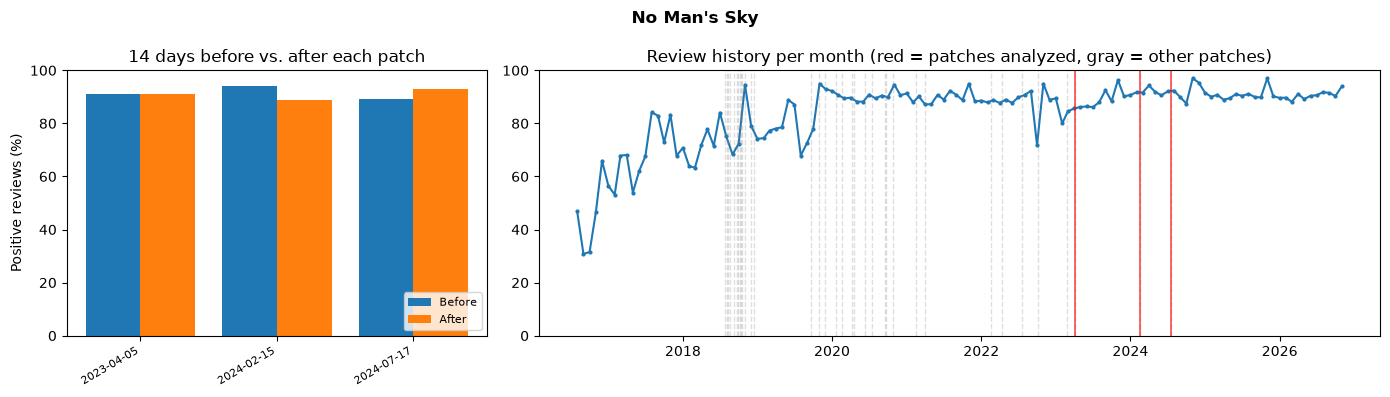

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,1023,91.3,53.5,14.0
After,3167,91.4,47.0,13.0


,word,times_after,times_before
0,survival,20,0
1,controller,14,0
2,map,14,0
3,menu,13,0
4,trial,13,0
5,weekend,13,0
6,fixed,12,0
7,tutorial,25,1
8,non,11,0
9,alien,11,0


**Summary:** Across 3 patch(es), positive reviews stayed about the same after updates (average change -0.4 points, from 91.4% to 91.0%). Best reaction: *Introducing Worlds Part I - the 5.0 update* (2024-07-17, +3.9). Worst reaction: *Introducing..the OMEGA update!* (2024-02-15, -5.3). Words rising in negative reviews after patches: survival, controller, map, menu, trial.

---
### Helldivers 2  
*Steam app 553850 · Live-service*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2025-09-24,State of the Game Update #1,1400,1398,64.5,67.1,2.6
1,2026-05-21,Optimizing Liberty - Incoming Patch: 27th May,1400,1398,48.4,64.7,16.3
2,2026-08-12,HELLDIVERS 2 Devoid of Liberty Update Out Now,1228,1400,80.0,81.4,1.5


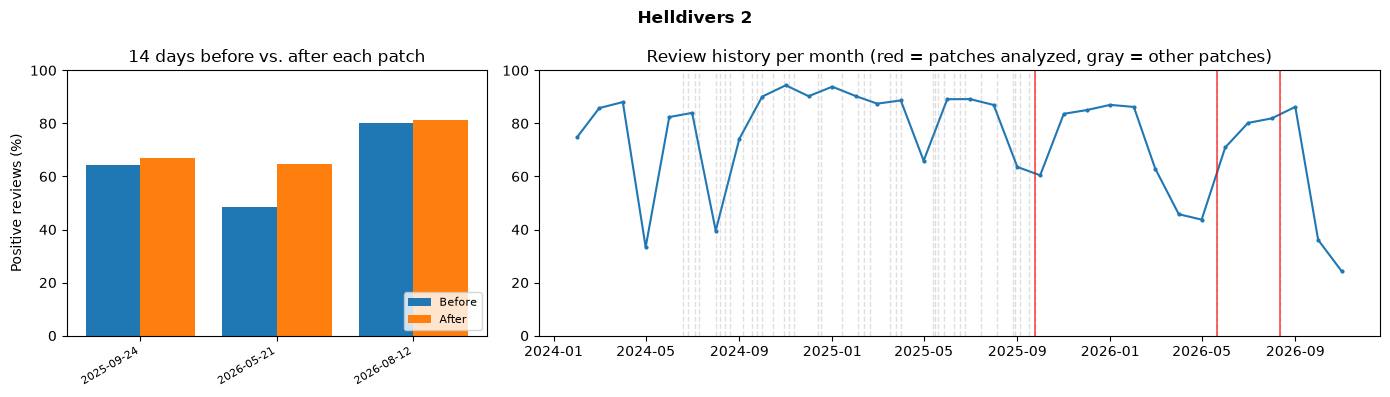

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,4028,63.6,111.7,13.0
After,4196,71.1,84.4,10.0


,word,times_after,times_before
0,hachimi,48,0
1,nameru,12,0
2,ashiga,12,0
3,requirements,10,0
4,intro,8,0
5,ten,7,0
6,sides,6,0
7,capped,6,0
8,lfd,6,0
9,accessories,6,0


**Summary:** Across 3 patch(es), positive reviews rose after updates (average change +6.8 points, from 64.3% to 71.1%). Best reaction: *Optimizing Liberty - Incoming Patch: 27th May* (2026-05-21, +16.3). Worst reaction: *HELLDIVERS 2 Devoid of Liberty Update Out Now* (2026-08-12, +1.5). Words rising in negative reviews after patches: hachimi, nameru, ashiga, requirements, intro.

---
### Elden Ring  
*Steam app 1245620 · Content updates*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2024-10-17,Patch Notes Version 1.16,1400,1381,95.4,93.5,-1.9
1,2025-08-21,ELDEN RING - Patch Notes Version 1.16.1,1375,1241,94.0,94.4,0.5
2,2026-08-27,Patch Notes Version 1.17,1132,1385,94.1,83.0,-11.1


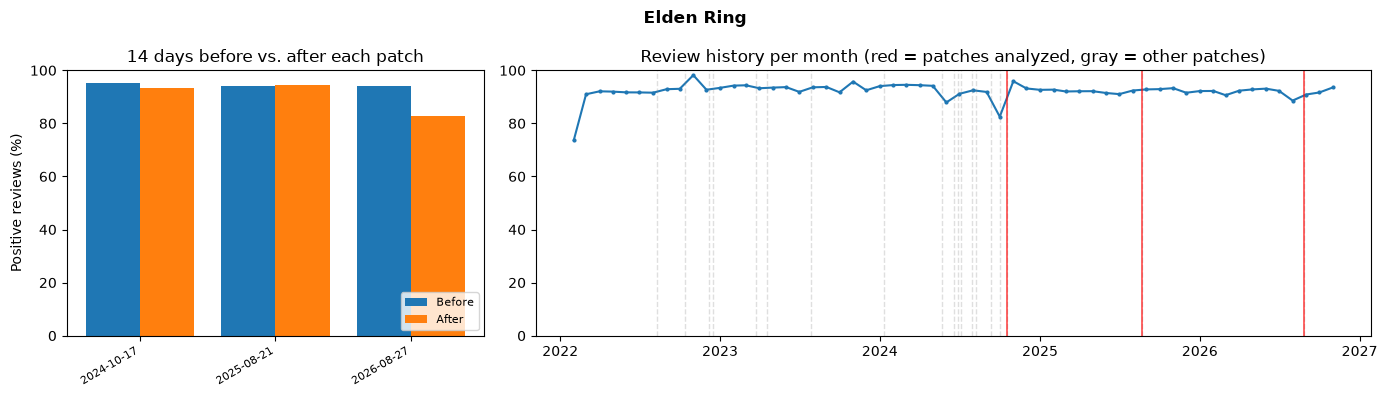

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,3907,94.5,101.8,6.0
After,4007,90.1,103.9,6.0


,word,times_after,times_before
0,armour,24,0
1,microtransactions,17,0
2,pack,17,0
3,edition,15,0
4,microtransaction,15,0
5,fromsoftware,42,2
6,horse,65,4
7,content,38,2
8,oasis,11,0
9,armor,46,3


**Summary:** Across 3 patch(es), positive reviews fell after updates (average change -4.2 points, from 94.5% to 90.3%). Best reaction: *ELDEN RING - Patch Notes Version 1.16.1* (2025-08-21, +0.5). Worst reaction: *Patch Notes Version 1.17* (2026-08-27, -11.1). Words rising in negative reviews after patches: armour, microtransactions, pack, edition, microtransaction.

---
### Counter-Strike 2  
*Steam app 730 · Live-service*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2026-10-22,Counter-Strike 2 Update,1400,1400,76.7,75.9,-0.9
1,2026-10-28,Counter-Strike 2 Update,1400,1400,75.9,79.9,3.9
2,2026-11-05,Counter-Strike 2 Update,1400,1351,77.8,79.9,2.1


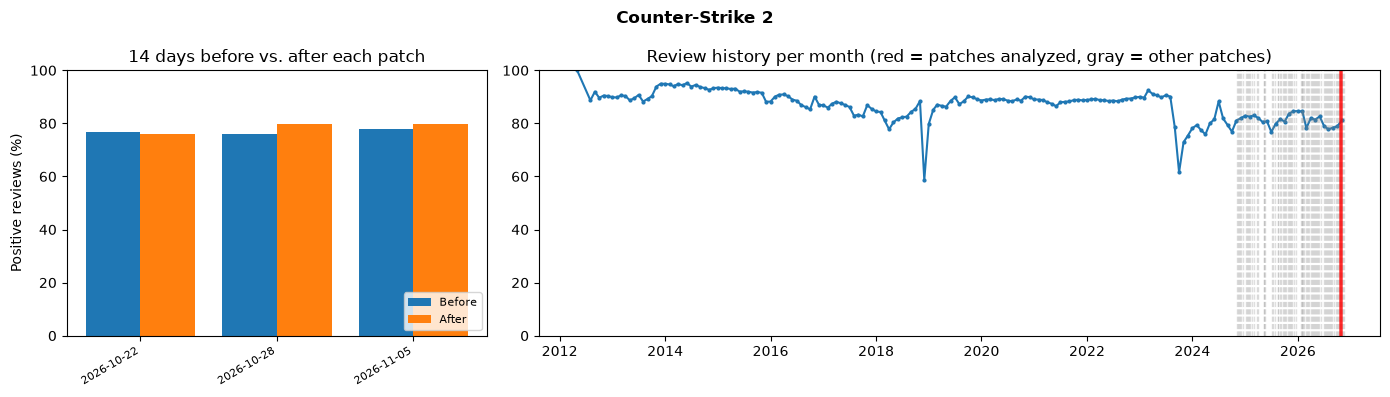

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,4200,76.8,115.5,4.0
After,4151,78.5,106.8,4.0


,word,times_after,times_before
0,foi,6,0
1,agora,6,0
2,pra,6,0
3,jogar,6,0
4,jogo,5,0
5,recomend,5,0
6,million,5,0
7,extremely,5,0
8,elo,14,2
9,four,4,0


**Summary:** Across 3 patch(es), positive reviews rose after updates (average change +1.7 points, from 76.8% to 78.5%). Best reaction: *Counter-Strike 2 Update* (2026-10-28, +3.9). Worst reaction: *Counter-Strike 2 Update* (2026-10-22, -0.9). Words rising in negative reviews after patches: foi, agora, pra, jogar, jogo.

---
### Dota 2  
*Steam app 570 · Live-service*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2026-07-01,Dota 2 Update - 7/1/2026,1148,1308,75.4,75.3,-0.1
1,2026-07-30,Gameplay Patch 7.41e and Summer Scrub,1235,1323,78.6,72.3,-6.4
2,2026-09-15,7.41f Gameplay Patch,1392,1369,75.0,73.9,-1.1


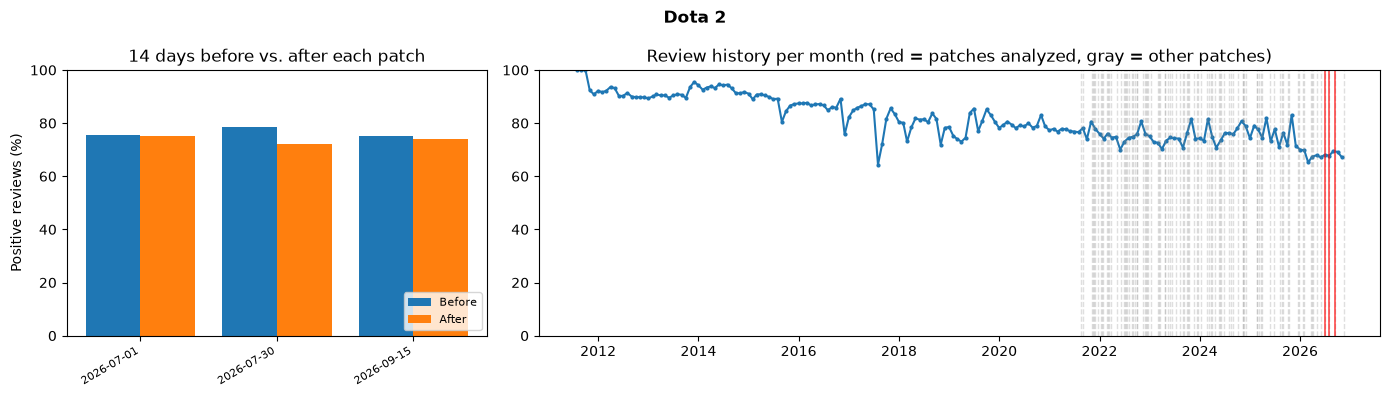

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,3775,76.3,931.1,3.0
After,4000,73.8,1009.3,3.0


,word,times_after,times_before
0,reccomend,21,0
1,xddddddddddddddddddddd,21,0
2,gay,61,2
3,xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx,15,0
4,thanks,13,0
5,waiting,7,0
6,letting,6,0
7,taken,6,0
8,guy,6,0
9,govno,6,0


**Summary:** Across 3 patch(es), positive reviews fell after updates (average change -2.5 points, from 76.4% to 73.8%). Best reaction: *Dota 2 Update - 7/1/2026* (2026-07-01, -0.1). Worst reaction: *Gameplay Patch 7.41e and Summer Scrub* (2026-07-30, -6.4). Words rising in negative reviews after patches: reccomend, xddddddddddddddddddddd, gay, xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx, thanks.

---
### Apex Legends  
*Steam app 1172470 · Live-service*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2026-10-20,Apex Legends: Latest Update 10/20/2026,933,866,67.4,71.2,3.8
1,2026-10-28,Apex Legends: Latest Update - 10/26/2026,877,876,71.4,70.8,-0.6
2,2026-11-02,Apex Legends™: Cipher Patch Notes,822,942,71.3,70.2,-1.1


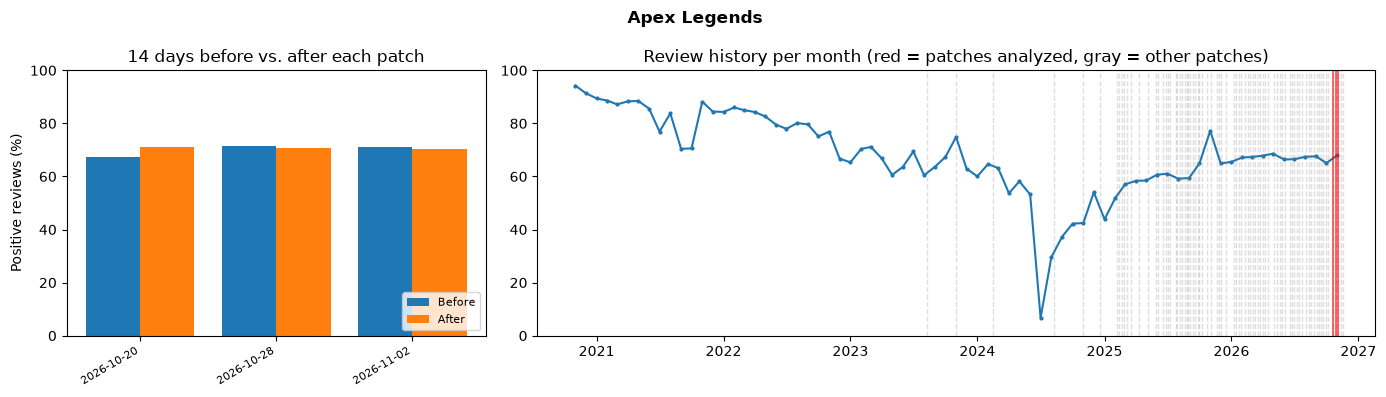

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,2632,69.9,92.0,5.0
After,2684,70.7,113.6,5.0


,word,times_after,times_before
0,drone,12,0
1,tell,10,0
2,xbox,10,0
3,died,10,0
4,list,27,2
5,manually,8,0
6,abilities,8,0
7,sweat,8,0
8,pro,7,0
9,roster,7,0


**Summary:** Across 3 patch(es), positive reviews rose after updates (average change +0.7 points, from 70.0% to 70.7%). Best reaction: *Apex Legends: Latest Update 10/20/2026* (2026-10-20, +3.8). Worst reaction: *Apex Legends™: Cipher Patch Notes* (2026-11-02, -1.1). Words rising in negative reviews after patches: drone, tell, xbox, died, list.

---
### PUBG: BATTLEGROUNDS  
*Steam app 578080 · Live-service*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2026-09-09,Map Service Report - Update 43.1,777,975,72.6,50.6,-22.0
1,2026-10-13,Patch Notes - Update 43.2,962,675,40.2,61.6,21.4
2,2026-11-03,Map Service Report - Update 44.1,574,607,64.1,69.9,5.7


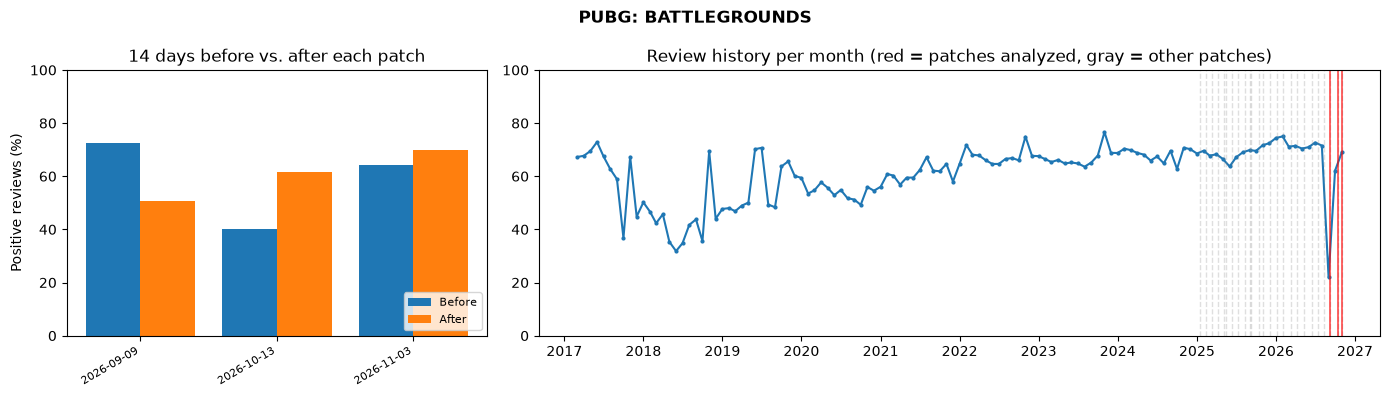

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,2313,57.0,61.6,3.0
After,2257,59.1,76.2,4.0


,word,times_after,times_before
0,xem,11,0
1,thay,9,0
2,vie,7,0
3,tai,7,0
4,tuy,14,1
5,star,6,0
6,kor,6,0
7,bir,6,0
8,point,17,2
9,along,5,0


**Summary:** Across 3 patch(es), positive reviews rose after updates (average change +1.7 points, from 59.0% to 60.7%). Best reaction: *Patch Notes - Update 43.2* (2026-10-13, +21.4). Worst reaction: *Map Service Report - Update 43.1* (2026-09-09, -22.0). Words rising in negative reviews after patches: xem, thay, vie, tai, tuy.

---
### Rust  
*Steam app 252490 · Live-service*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2025-09-25,COMMUNITY UPDATE 267,1175,1314,83.3,77.2,-6.1
1,2026-01-22,COMMUNITY UPDATE 268,1351,1319,82.2,83.0,0.9
2,2026-02-05,NAVAL UPDATE,1321,1400,83.1,81.4,-1.7


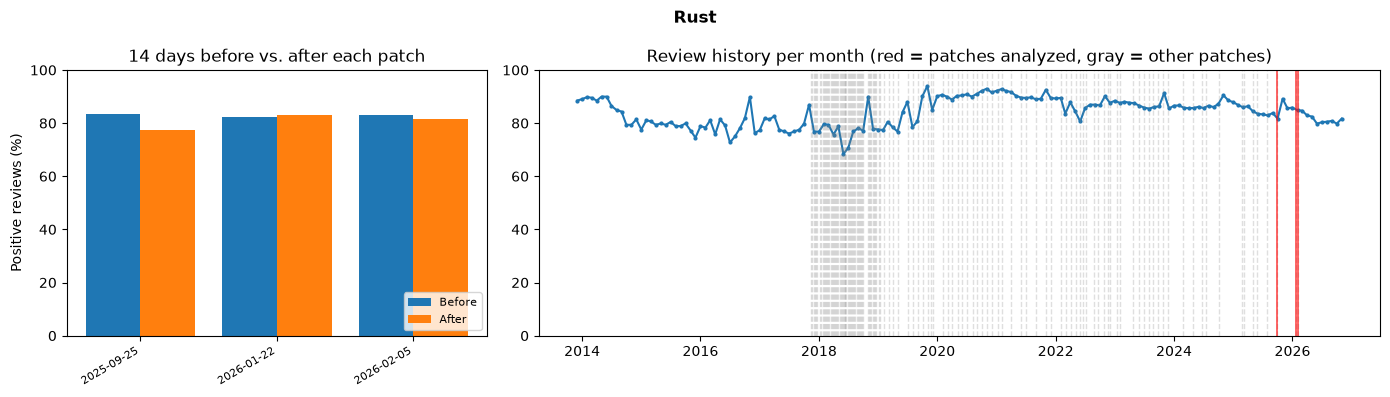

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,3847,82.8,165.4,5.0
After,4033,80.6,157.7,6.0


,word,times_after,times_before
0,zergs,14,0
1,recent,14,0
2,fragments,24,1
3,fragment,9,0
4,seems,8,0
5,tier,8,0
6,bugs,8,0
7,blueprint,16,1
8,update,73,8
9,workbench,15,1


**Summary:** Across 3 patch(es), positive reviews fell after updates (average change -2.3 points, from 82.9% to 80.6%). Best reaction: *COMMUNITY UPDATE 268* (2026-01-22, +0.9). Worst reaction: *COMMUNITY UPDATE 267* (2025-09-25, -6.1). Words rising in negative reviews after patches: zergs, recent, fragments, fragment, seems.

---
### Destiny 2  
*Steam app 1085660 · Live-service*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2025-09-04,Destiny 2: Ash & Iron Major Update Trailer,673,999,55.4,45.4,-10.0
1,2026-06-09,Destiny 2: Monument of Triumph Update,1400,1400,87.6,87.3,-0.3
2,2026-10-29,Bungie Community Update – October 2026,538,407,85.5,82.8,-2.7


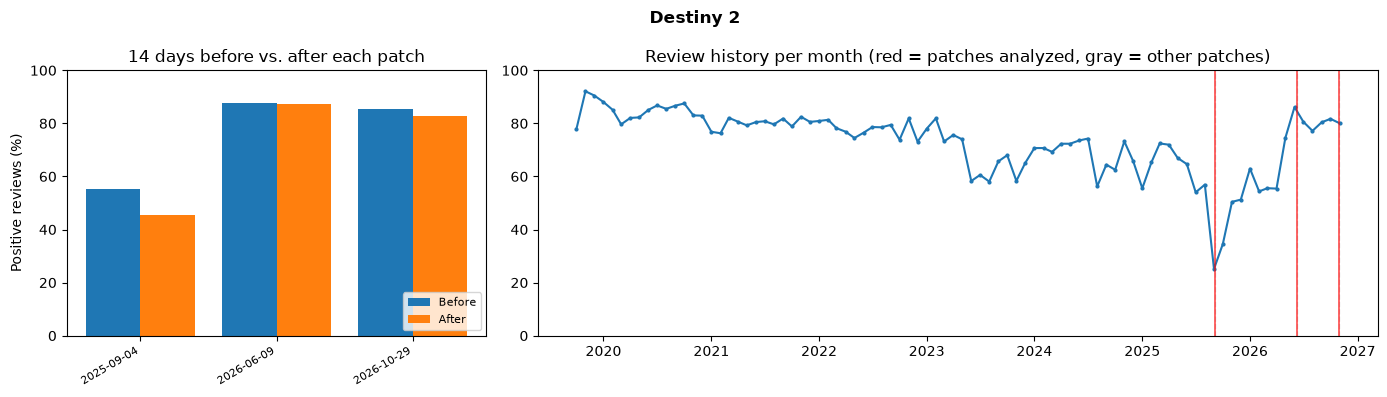

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,2611,78.9,283.5,11.0
After,2806,71.7,241.0,11.0


,word,times_after,times_before
0,iron,35,0
1,ash,25,0
2,kepler,84,3
3,charlie,16,0
4,keeping,10,0
5,eververse,19,1
6,downs,9,0
7,collection,8,0
8,media,8,0
9,premium,8,0


**Summary:** Across 3 patch(es), positive reviews fell after updates (average change -4.3 points, from 76.2% to 71.8%). Best reaction: *Destiny 2: Monument of Triumph Update* (2026-06-09, -0.3). Worst reaction: *Destiny 2: Ash & Iron Major Update Trailer* (2025-09-04, -10.0). Words rising in negative reviews after patches: iron, ash, kepler, charlie, keeping.

---
### Warframe  
*Steam app 230410 · Live-service*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2025-11-28,The Old Peace Update Launches December 10,915,1138,93.3,94.0,0.7
1,2025-12-10,The Old Peace: Free Update Available Now,1097,1400,94.6,92.5,-2.1
2,2026-04-14,Devstream #195 - Unannounced 2026 Update!,1221,1094,91.8,93.0,1.2


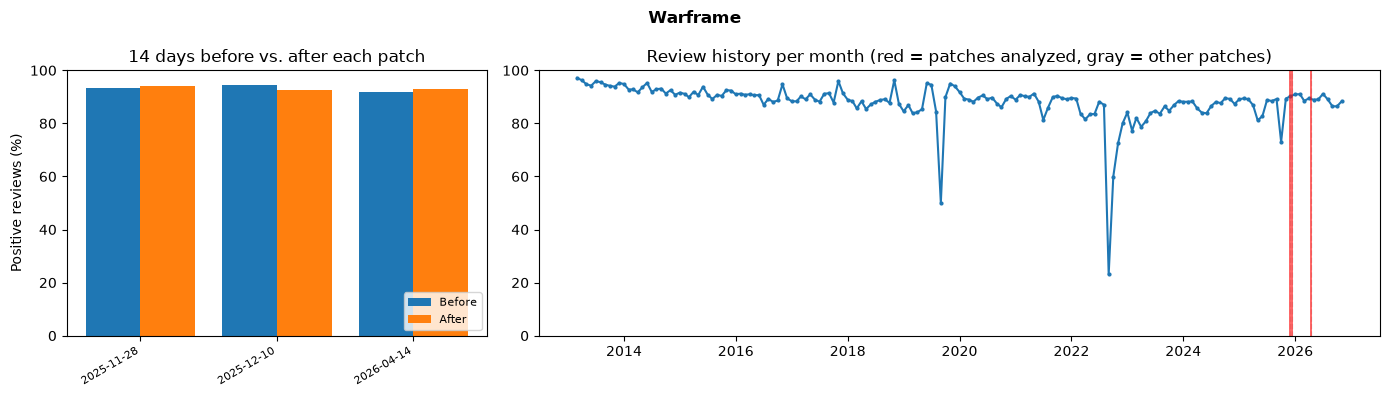

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,3233,93.2,167.3,7.0
After,3632,93.1,196.4,7.0


,word,times_after,times_before
0,explained,10,0
1,lore,7,0
2,health,7,0
3,opinion,7,0
4,slash,7,0
5,designed,6,0
6,upgrade,6,0
7,challenge,6,0
8,bounties,6,0
9,operator,6,0


**Summary:** Across 3 patch(es), positive reviews stayed about the same after updates (average change -0.1 points, from 93.3% to 93.2%). Best reaction: *Devstream #195 - Unannounced 2026 Update!* (2026-04-14, +1.2). Worst reaction: *The Old Peace: Free Update Available Now* (2025-12-10, -2.1). Words rising in negative reviews after patches: explained, lore, health, opinion, slash.

---
### Dead by Daylight  
*Steam app 381210 · Live-service*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2026-10-20,10.2.2 | Bugfix Patch,1270,1348,72.5,62.0,-10.5
1,2026-10-28,10.3.0 | Terrifier PTB Patch Notes,1277,1381,70.9,43.8,-27.1
2,2026-11-09,10.2.2b Backend Patch,1395,1070,47.2,66.6,19.5


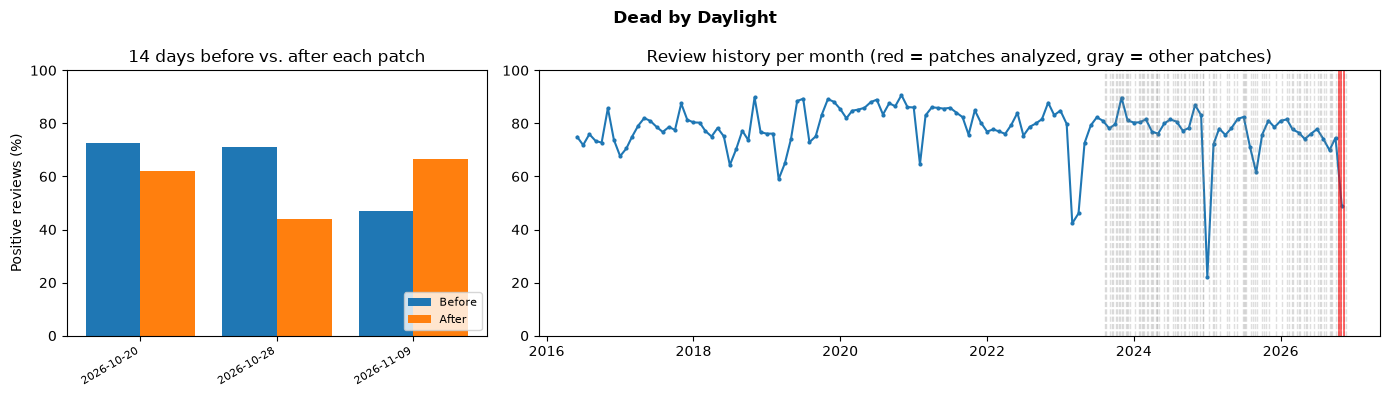

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,3942,63.0,82.5,8.0
After,3799,56.7,91.4,9.0


,word,times_after,times_before
0,pls,18,0
1,opp,17,0
2,che,10,0
3,lazier,8,0
4,manager,8,0
5,bent,8,0
6,sono,8,0
7,chud,7,0
8,doxx,7,0
9,lethality,7,0


**Summary:** Across 3 patch(es), positive reviews fell after updates (average change -6.1 points, from 63.5% to 57.5%). Best reaction: *10.2.2b Backend Patch* (2026-11-09, +19.5). Worst reaction: *10.3.0 | Terrifier PTB Patch Notes* (2026-10-28, -27.1). Words rising in negative reviews after patches: pls, opp, che, lazier, manager.

---
### Marvel Rivals  
*Steam app 2767030 · Live-service*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2026-10-22,Marvel Rivals Version 20261022 Patch Notes,1372,1230,53.1,50.8,-2.3
1,2026-10-29,Marvel Rivals Version 20261029 Patch Notes,1332,1143,51.1,53.1,2.0
2,2026-11-05,Marvel Rivals Version 20261105 Patch Notes,1234,1213,50.5,52.6,2.1


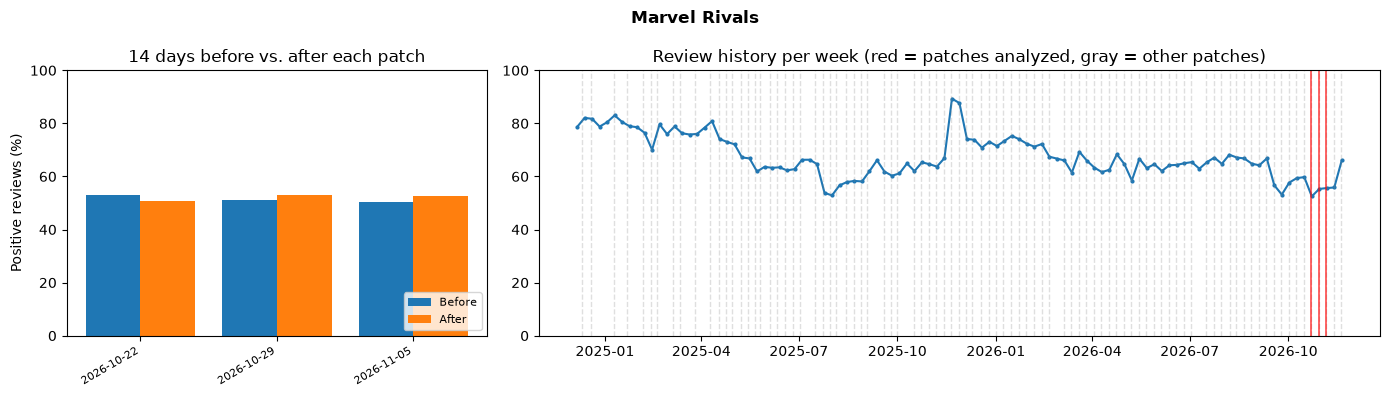

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,3938,51.6,121.3,7.0
After,3586,52.1,137.0,7.0


,word,times_after,times_before
0,nightmare,278,4
1,melee,8,0
2,daredevil,7,0
3,quickmatch,6,0
4,machine,6,0
5,cough,6,0
6,upon,6,0
7,school,6,0
8,changing,5,0
9,stomped,5,0


**Summary:** Across 3 patch(es), positive reviews rose after updates (average change +0.6 points, from 51.6% to 52.2%). Best reaction: *Marvel Rivals Version 20261105 Patch Notes* (2026-11-05, +2.1). Worst reaction: *Marvel Rivals Version 20261022 Patch Notes* (2026-10-22, -2.3). Words rising in negative reviews after patches: nightmare, melee, daredevil, quickmatch, machine.

---
### Baldur's Gate 3  
*Steam app 1086940 · Content updates*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2025-11-20,Hotfix #35 Now Live!,1311,1367,96.0,97.3,1.3
1,2025-12-01,Community Update #36 A Very Moddy Christmas,1366,1287,97.5,95.1,-2.4
2,2026-03-26,Hotfix #36 Now Live!,1269,1254,95.7,95.3,-0.4


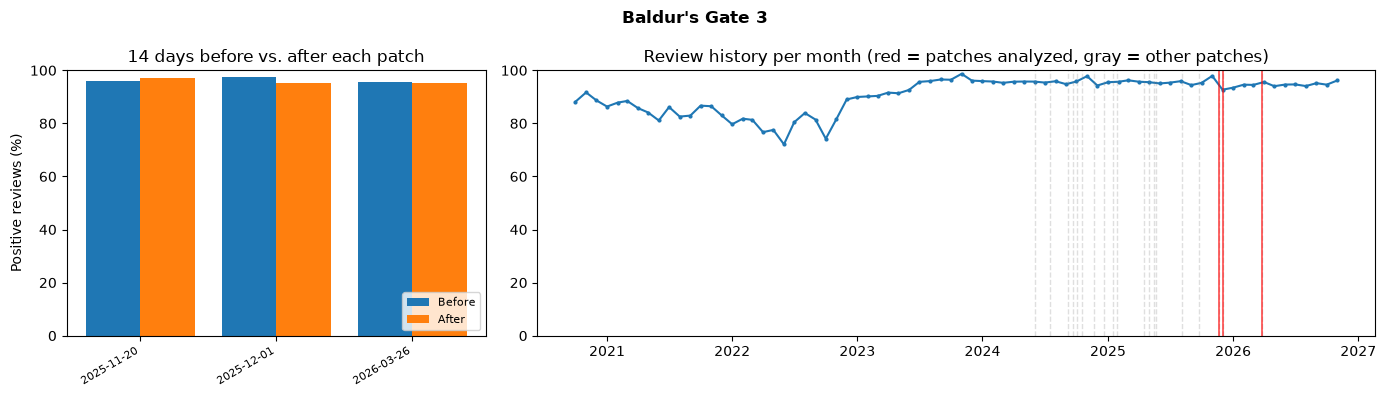

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,3946,96.4,145.4,9.0
After,3908,95.9,148.5,9.0


,word,times_after,times_before
0,fuck,12,0
1,crashes,7,0
2,won,7,0
3,totally,7,0
4,files,7,0
5,mods,14,1
6,area,6,0
7,suddenly,6,0
8,little,19,2
9,broken,12,1


**Summary:** Across 3 patch(es), positive reviews stayed about the same after updates (average change -0.5 points, from 96.4% to 95.9%). Best reaction: *Hotfix #35 Now Live!* (2025-11-20, +1.3). Worst reaction: *Community Update #36 A Very Moddy Christmas* (2025-12-01, -2.4). Words rising in negative reviews after patches: fuck, crashes, won, totally, files.

---
### Terraria  
*Steam app 105600 · Content updates*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2021-11-18,An Eye For An Eye: Terraria x Don't Starve Tog...,1400,1400,98.1,99.1,1.0
1,2022-02-14,Sharing the Love - Terraria Update News!,1400,1400,97.6,97.9,0.3
2,2022-02-24,Terraria 1.4.3.3 - Steam Deck Optimization Upd...,1400,1400,97.9,98.4,0.6


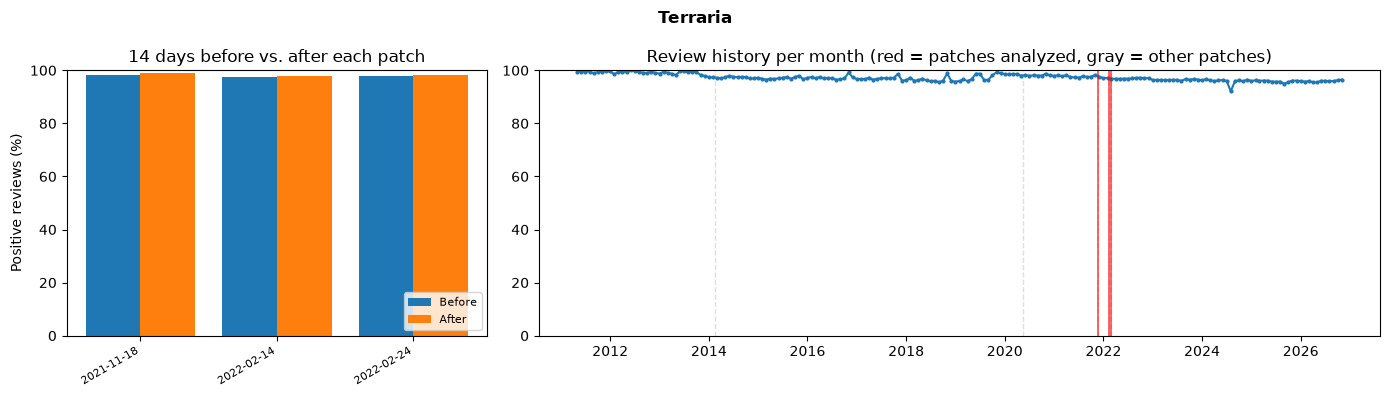

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,4200,97.9,54.0,4.0
After,4200,98.5,70.2,4.0


,word,times_after,times_before
0,server,4,0
1,sword,3,0
2,shit,7,1
3,killed,4,1
4,hate,3,2
5,times,3,2
6,world,4,3
7,keep,5,4
8,made,4,4
9,hours,3,3


**Summary:** Across 3 patch(es), positive reviews rose after updates (average change +0.6 points, from 97.9% to 98.5%). Best reaction: *An Eye For An Eye: Terraria x Don't Starve Together Crossover Update Out Now!* (2021-11-18, +1.0). Worst reaction: *Sharing the Love - Terraria Update News!* (2022-02-14, +0.3). Words rising in negative reviews after patches: server, sword, shit, killed, hate.

---
### Stardew Valley  
*Steam app 413150 · Content updates*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2024-11-04,1.6.9 Update Now Available,1354,1400,98.7,98.6,-0.0
1,2024-11-12,1.6.14 Update,1383,1392,98.7,98.7,0.0
2,2024-12-20,Stardew Valley 1.6.15 Patch now available,1400,1400,98.6,98.9,0.2


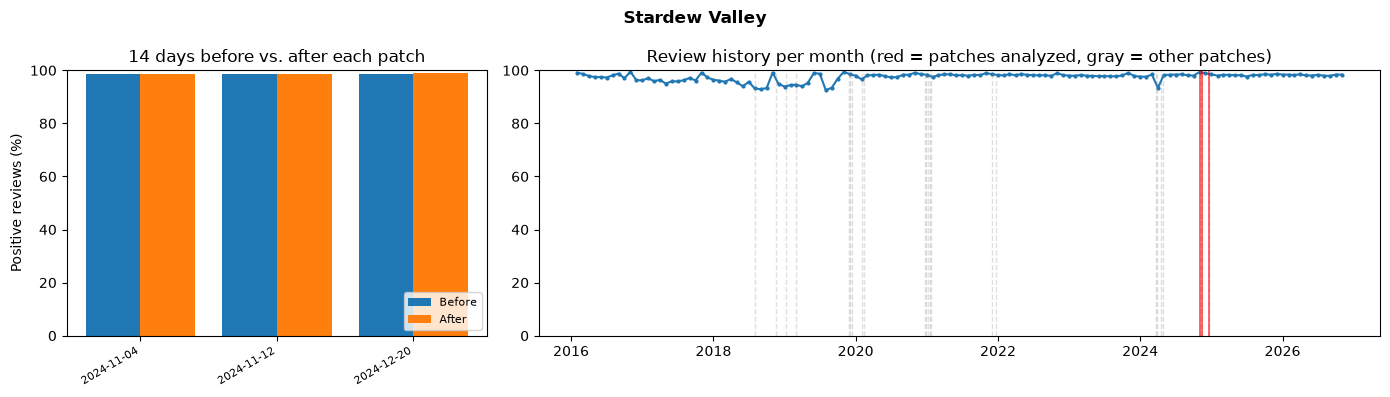

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,4137,98.7,66.4,7.0
After,4192,98.7,54.7,7.0


,word,times_after,times_before
0,maybe,8,1
1,graphics,3,0
2,early,3,0
3,bed,3,0
4,farming,4,1
5,missing,4,1
6,someone,4,1
7,understand,6,2
8,man,6,2
9,mechanics,3,1


**Summary:** Across 3 patch(es), positive reviews stayed about the same after updates (average change +0.1 points, from 98.7% to 98.7%). Best reaction: *Stardew Valley 1.6.15 Patch now available* (2024-12-20, +0.2). Worst reaction: *1.6.9 Update Now Available* (2024-11-04, -0.0). Words rising in negative reviews after patches: maybe, graphics, early, bed, farming.

---
### Valheim  
*Steam app 892970 · Early access*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2026-10-06,Patch 1.0.17,1399,1400,81.8,81.3,-0.5
1,2026-10-15,Patch 1.0.20,1400,1332,82.1,78.2,-3.8
2,2026-10-28,Patch 1.0.21,1337,1003,78.7,81.8,3.1


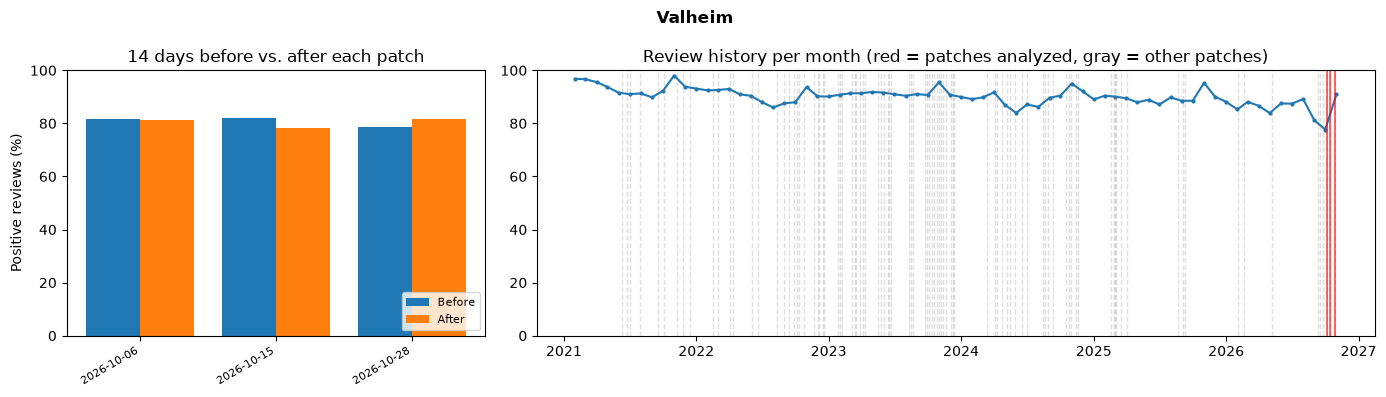

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,4136,80.9,158.1,11.0
After,3735,80.3,168.3,12.0


,word,times_after,times_before
0,elephants,5,0
1,bush,4,0
2,output,4,0
3,atleast,4,0
4,absurdly,4,0
5,tacked,4,0
6,neutered,4,0
7,restart,3,0
8,digging,3,0
9,wouldn,3,0


**Summary:** Across 3 patch(es), positive reviews stayed about the same after updates (average change -0.4 points, from 80.8% to 80.4%). Best reaction: *Patch 1.0.21* (2026-10-28, +3.1). Worst reaction: *Patch 1.0.20* (2026-10-15, -3.8). Words rising in negative reviews after patches: elephants, bush, output, atleast, absurdly.

---
### Palworld  
*Steam app 1623730 · Early access*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2026-09-07,v1.0.4: Balance Adjustments & Bug Fixes,1400,1377,94.1,95.6,1.5
1,2026-09-15,v1.0.5: Bug fixes,1400,1180,95.4,95.7,0.3
2,2026-10-20,Global Popularity Poll 2026 Results & New Update,927,668,96.0,93.7,-2.3


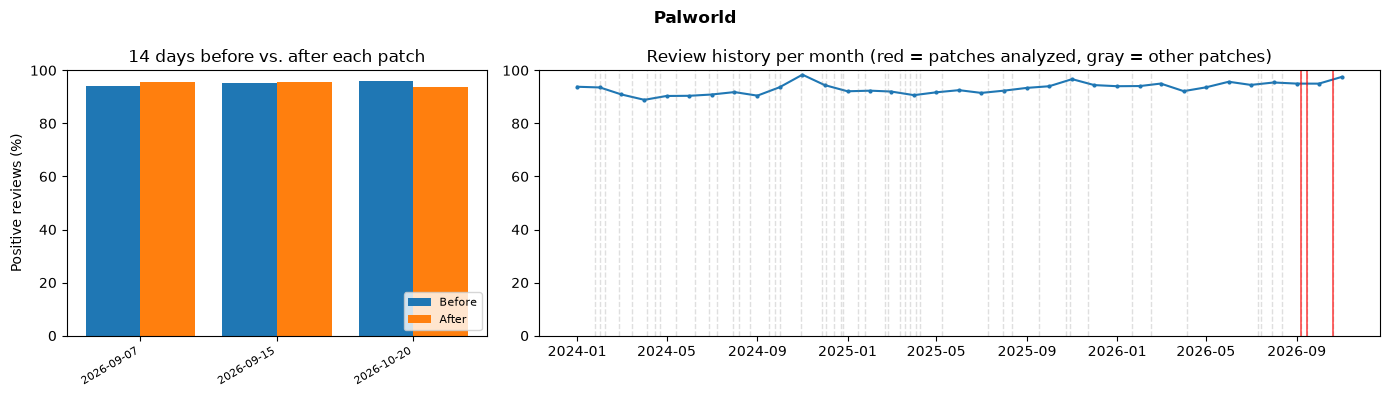

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,3727,95.0,72.2,9.0
After,3225,95.2,81.6,8.0


,word,times_after,times_before
0,eerily,10,0
1,pocket,10,0
2,pair,10,0
3,official,9,0
4,flaws,8,0
5,similarly,8,0
6,copying,8,0
7,immersion,7,0
8,servers,15,1
9,narrative,6,0


**Summary:** Across 3 patch(es), positive reviews stayed about the same after updates (average change -0.2 points, from 95.1% to 95.0%). Best reaction: *v1.0.4: Balance Adjustments & Bug Fixes* (2026-09-07, +1.5). Worst reaction: *Global Popularity Poll 2026 Results & New Update* (2026-10-20, -2.3). Words rising in negative reviews after patches: eerily, pocket, pair, official, flaws.

---
### Lethal Company  
*Steam app 1966720 · Early access*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2025-06-04,V71 Bug fix patch,802,997,95.4,94.8,-0.6
1,2025-10-04,Handy Patch V73,504,645,92.5,93.3,0.9
2,2026-04-05,Version 80 - The Blooming Update,856,1062,93.7,94.7,1.0


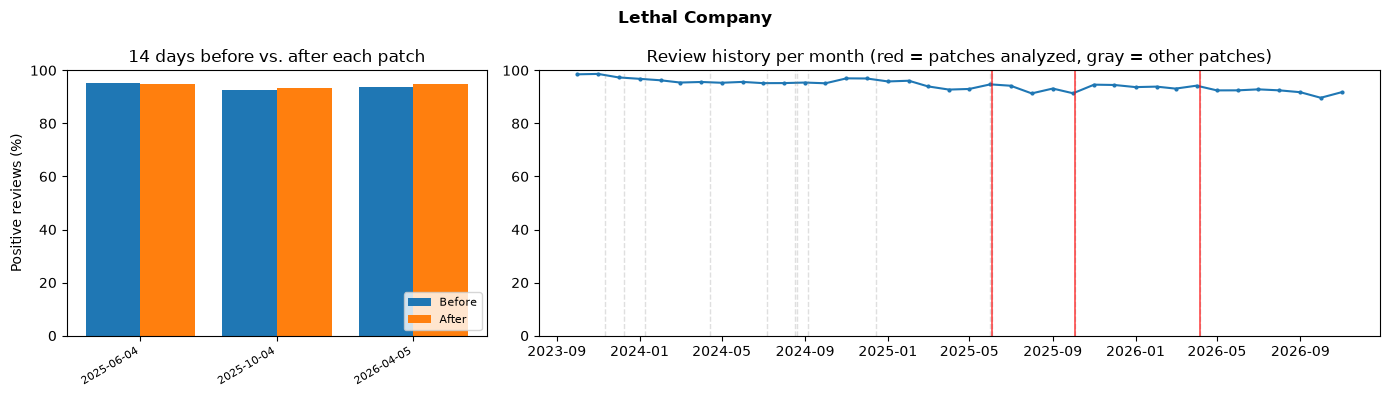

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,2162,94.0,31.2,6.0
After,2704,94.4,30.6,5.0


,word,times_after,times_before
0,everything,8,0
1,far,7,0
2,story,7,0
3,started,5,0
4,stuff,5,0
5,quite,5,0
6,real,5,0
7,actual,5,0
8,mean,5,0
9,either,5,0


**Summary:** Across 3 patch(es), positive reviews stayed about the same after updates (average change +0.4 points, from 93.8% to 94.3%). Best reaction: *Version 80 - The Blooming Update* (2026-04-05, +1.0). Worst reaction: *V71 Bug fix patch* (2025-06-04, -0.6). Words rising in negative reviews after patches: everything, far, story, started, stuff.

---
### Cities: Skylines II  
*Steam app 949230 · Early access*

,patch_date,patch_title,reviews_before,reviews_after,positive_percent_before,positive_percent_after,change_points
0,2026-05-27,Patch 1.5.9f1 - Morning Dew,238,233,71.8,79.8,8.0
1,2026-06-22,Patch 1.6.0f1 - Summer Solstice,266,319,77.4,75.9,-1.6
2,2026-09-15,Patch 1.6.2f1 - Autumn Breeze,236,578,68.6,42.9,-25.7


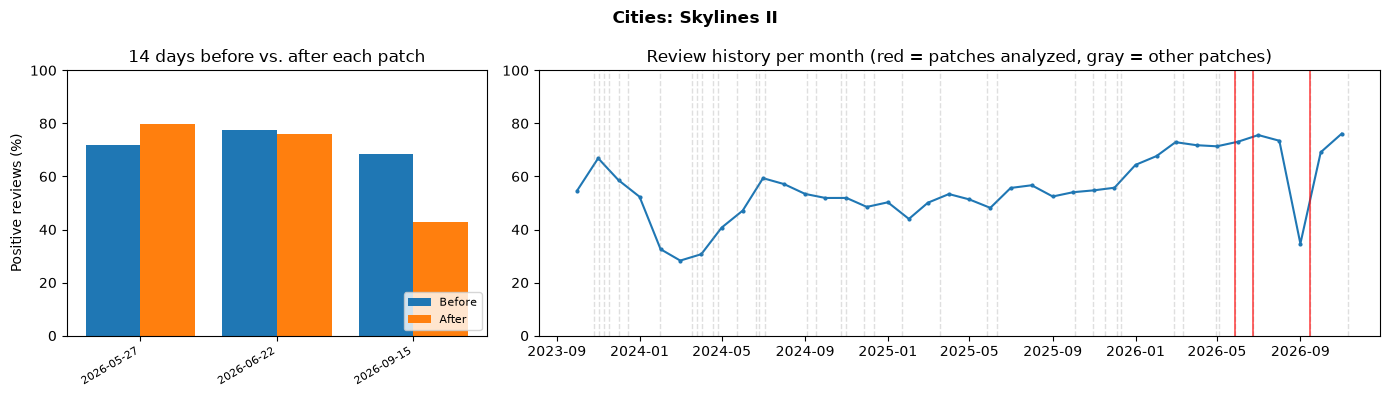

,reviews,positive_percent,median_playtime_hours,median_review_words
period,,,,
Before,740,72.8,45.0,16.0
After,1130,59.8,37.2,16.0


,word,times_after,times_before
0,turkish,57,0
1,atat,86,1
2,historical,41,0
3,mustafa,38,0
4,kemal,38,0
5,racist,29,0
6,discord,28,0
7,moderation,24,0
8,bir,22,0
9,profile,21,0


**Summary:** Across 3 patch(es), positive reviews fell after updates (average change -6.4 points, from 72.6% to 66.2%). Best reaction: *Patch 1.5.9f1 - Morning Dew* (2026-05-27, +8.0). Worst reaction: *Patch 1.6.2f1 - Autumn Breeze* (2026-09-15, -25.7). Words rising in negative reviews after patches: turkish, atat, historical, mustafa, kemal.

In [28]:
# Run the case study for every game (change this list to only run a few)
CASE_STUDY_GAMES = list(GAMES)

case_rows = []
for game in CASE_STUDY_GAMES:
    row = case_study(game)
    if row:
        case_rows.append(row)

In [29]:
# One row per game saved for the report
case_studies_df = pd.DataFrame(case_rows).sort_values("avg_change", ascending=False)
case_studies_df.to_csv("case_studies_summary.csv", index=False)
display(case_studies_df.round(1).reset_index(drop=True))

,game,app_id,type,patches,avg_before,avg_after,avg_change,best_patch,best_change,worst_patch,worst_change,median_playtime_before,median_playtime_after,rising_negative_words
0,Helldivers 2,553850,Live-service,3,64.3,71.1,6.8,Optimizing Liberty - Incoming Patch: 27th May,16.3,HELLDIVERS 2 Devoid of Liberty Update Out Now,1.5,111.7,84.4,"hachimi, nameru, ashiga, requirements, intro"
1,Counter-Strike 2,730,Live-service,3,76.8,78.5,1.7,Counter-Strike 2 Update,3.9,Counter-Strike 2 Update,-0.9,115.5,106.8,"foi, agora, pra, jogar, jogo"
2,PUBG: BATTLEGROUNDS,578080,Live-service,3,59.0,60.7,1.7,Patch Notes - Update 43.2,21.4,Map Service Report - Update 43.1,-22.0,61.6,76.2,"xem, thay, vie, tai, tuy"
3,Apex Legends,1172470,Live-service,3,70.0,70.7,0.7,Apex Legends: Latest Update 10/20/2026,3.8,Apex Legends™: Cipher Patch Notes,-1.1,92.0,113.6,"drone, tell, xbox, died, list"
4,Terraria,105600,Content updates,3,97.9,98.5,0.6,An Eye For An Eye: Terraria x Don't Starve Tog...,1.0,Sharing the Love - Terraria Update News!,0.3,54.0,70.2,"server, sword, shit, killed, hate"
5,Marvel Rivals,2767030,Live-service,3,51.6,52.2,0.6,Marvel Rivals Version 20261105 Patch Notes,2.1,Marvel Rivals Version 20261022 Patch Notes,-2.3,121.3,137.0,"nightmare, melee, daredevil, quickmatch, machine"
6,Lethal Company,1966720,Early access,3,93.8,94.3,0.4,Version 80 - The Blooming Update,1.0,V71 Bug fix patch,-0.6,31.2,30.6,"everything, far, story, started, stuff"
7,Stardew Valley,413150,Content updates,3,98.7,98.7,0.1,Stardew Valley 1.6.15 Patch now available,0.2,1.6.9 Update Now Available,-0.0,66.4,54.7,"maybe, graphics, early, bed, farming"
8,Warframe,230410,Live-service,3,93.3,93.2,-0.1,Devstream #195 - Unannounced 2026 Update!,1.2,The Old Peace: Free Update Available Now,-2.1,167.3,196.4,"explained, lore, health, opinion, slash"
9,Palworld,1623730,Early access,3,95.1,95.0,-0.2,v1.0.4: Balance Adjustments & Bug Fixes,1.5,Global Popularity Poll 2026 Results & New Update,-2.3,72.2,81.6,"eerily, pocket, pair, official, flaws"
